In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
oxford_pet_dataset_path = kagglehub.dataset_download('julinmaloof/the-oxfordiiit-pet-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'the-oxfordiiit-pet-dataset' dataset.
Data source import complete.


In [ ]:
# -------------------------
# Imports
# -------------------------
import os
import random
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import torchvision.transforms as T
from torchvision.transforms import InterpolationMode

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# pretrained backbones
import torchvision
from torchvision.models import (
    mobilenet_v2, MobileNet_V2_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    densenet121, DenseNet121_Weights,
)

# -------------------------
# Reproducibility + device
# -------------------------
def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
# =========================================
#  AMP (autocast/scaler)
# =========================================
def make_amp():
    from torch.amp import autocast, GradScaler
    autocast_ctx = lambda: autocast(device_type="cuda", enabled=(DEVICE == "cuda"))
    scaler = GradScaler("cuda", enabled=(DEVICE == "cuda"))
    return autocast_ctx, scaler

AUT, SCALER = make_amp()


# File

In [ ]:
import kagglehub
DATA_ROOT = kagglehub.dataset_download("julinmaloof/the-oxfordiiit-pet-dataset")
print("Downloaded dataset to:", DATA_ROOT)


Using Colab cache for faster access to the 'the-oxfordiiit-pet-dataset' dataset.
Downloaded dataset to: /kaggle/input/the-oxfordiiit-pet-dataset


Paths

In [ ]:
@dataclass
class Paths:
    data_root: str = DATA_ROOT
    out_dir: str = "/kaggle/working"

    @property
    def images_dir(self):
        return os.path.join(self.data_root, "images")

    @property
    def annotations_dir(self):
        return os.path.join(self.data_root, "annotations")

    @property
    def trimaps_dir(self):
        return os.path.join(self.annotations_dir, "trimaps")

paths = Paths()
print("DATA_ROOT:", paths.data_root)
print("CHECKPOINT_DIR:", paths.out_dir)

DATA_ROOT: /kaggle/input/the-oxfordiiit-pet-dataset
CHECKPOINT_DIR: /kaggle/working


In [ ]:
# Resume helpers for a fresh Kaggle session.
# Put the downloaded checkpoint files into a Kaggle Dataset or the notebook's Input panel,
# then set CHECKPOINT_DIR to that mounted folder, for example:
# CHECKPOINT_DIR = "/kaggle/input/pet-checkpoints"
CHECKPOINT_DIR = "/kaggle/input/<your-checkpoint-dataset-folder>"


def load_checkpoint_payload(filename: str):
    path = os.path.join(CHECKPOINT_DIR, filename)
    payload = torch.load(path, map_location=DEVICE)
    if isinstance(payload, dict) and "model_state_dict" in payload:
        return path, payload
    return path, {"model_state_dict": payload}


def restore_model(model: nn.Module, filename: str, strict: bool = True):
    path, payload = load_checkpoint_payload(filename)
    model.load_state_dict(payload["model_state_dict"], strict=strict)
    print(f"Loaded weights from {path}")
    return payload


def resume_training_state(model: nn.Module, optimizer: torch.optim.Optimizer, filename: str):
    path, payload = load_checkpoint_payload(filename)
    model.load_state_dict(payload["model_state_dict"])
    if "optimizer_state_dict" in payload:
        optimizer.load_state_dict(payload["optimizer_state_dict"])
    start_epoch = int(payload.get("epoch", 0)) + 1
    history = payload.get("history", {})
    print(f"Resumed training from {path} at epoch {start_epoch}")
    return start_epoch, history, payload


# EDA

In [ ]:
import os

root = DATA_ROOT
images = os.listdir(paths.images_dir)
annotations = os.listdir(paths.trimaps_dir)

print("Dataset Statistics:")
print(f"Total images: {len(images)}")
print(f"Total segmentation masks (trimaps): {len(annotations)}")

Dataset Statistics:
Total images: 7393
Total segmentation masks (trimaps): 7390


In [ ]:
import os
# List contents of the dataset root to find the correct folders
print(f"Contents of {DATA_ROOT}:")
for item in os.listdir(DATA_ROOT):
    item_path = os.path.join(DATA_ROOT, item)
    if os.path.isdir(item_path):
        print(f"  [DIR]  {item}")
        # Peek inside one level deeper
        print(f"    Contains: {os.listdir(item_path)[:5]}")
    else:
        print(f"  [FILE] {item}")

Contents of /kaggle/input/the-oxfordiiit-pet-dataset:
  [DIR]  annotations
    Contains: ['xmls', 'README', 'test.txt', 'trainval.txt', 'list.txt']
  [DIR]  images
    Contains: ['american_pit_bull_terrier_16.jpg', 'leonberger_200.jpg', 'english_cocker_spaniel_35.jpg', 'Siamese_67.jpg', 'boxer_77.jpg']


In [ ]:
import os

# The Oxford-IIIT Pet dataset has a different structure than the code assumed.
# Let's count the files in the actual directories discovered.

images_path = paths.images_dir
annotations_path = paths.trimaps_dir

if os.path.exists(images_path):
    total_images = len([f for f in os.listdir(images_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    print(f"Total images in {images_path}: {total_images}")
else:
    print(f"Directory not found: {images_path}")

if os.path.exists(annotations_path):
    total_masks = len([f for f in os.listdir(annotations_path) if f.lower().endswith('.png')])
    print(f"Total segmentation masks in {annotations_path}: {total_masks}")
else:
    print(f"Directory not found: {annotations_path}")

Total images in /kaggle/input/the-oxfordiiit-pet-dataset/images: 7390
Total segmentation masks in /kaggle/input/the-oxfordiiit-pet-dataset/annotations/trimaps: 7390


In [ ]:
import os
import pandas as pd
import re

# Oxford-IIIT Pet dataset has labels in filenames: [Species]_[ID].jpg
def get_class_from_name(fname):
    match = re.match(r'^(.+)_\d+\.', fname)
    return match.group(1) if match else None

image_folder = paths.images_dir
if os.path.exists(image_folder):
    files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    data = []
    for f in files:
        cls = get_class_from_name(f)
        if cls: data.append(cls)

    # Aggregate counts to create df_counts for visualization
    df_counts = pd.DataFrame(data, columns=['class']).value_counts().reset_index(name='train')
    # Add a dummy test column so subsequent plotting cells don't fail
    df_counts['test'] = 0
    classes = sorted(df_counts['class'].unique())

    print(f"Found {len(classes)} classes from filenames.")
    print(df_counts.head())
else:
    print(f"Directory not found: {image_folder}")

Found 37 classes from filenames.
               class  train  test
0         Abyssinian    200     0
1             Bengal    200     0
2             Birman    200     0
3             Bombay    200     0
4  British_Shorthair    200     0


In [ ]:
import re

def get_class_from_filename(fname):
    # Filenames are like 'Abyssinian_123.jpg' or 'scottish_terrier_45.jpg'
    match = re.match(r'^(.+)_\d+\.(?:jpg|jpeg|png)$', fname, re.IGNORECASE)
    return match.group(1) if match else None

image_files = [f for f in os.listdir(paths.images_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
file_data = []

for f in image_files:
    cls = get_class_from_filename(f)
    if cls:
        file_data.append({'filename': f, 'class': cls})

df_counts = pd.DataFrame(file_data)
class_stats = df_counts['class'].value_counts().reset_index()
class_stats.columns = ['class', 'count']
classes = sorted(df_counts['class'].unique())

print(f"Found {len(classes)} classes.")
print(class_stats.head())
# Setting variables for compatibility with subsequent cells
# We'll treat the whole set as 'train' for the sake of the existing plot code
df_counts = class_stats.rename(columns={'count': 'train'})

Found 37 classes.
                       class  count
0  american_pit_bull_terrier    200
1                 leonberger    200
2     english_cocker_spaniel    200
3                    Siamese    200
4                      boxer    200


Class distribution plot (classification)

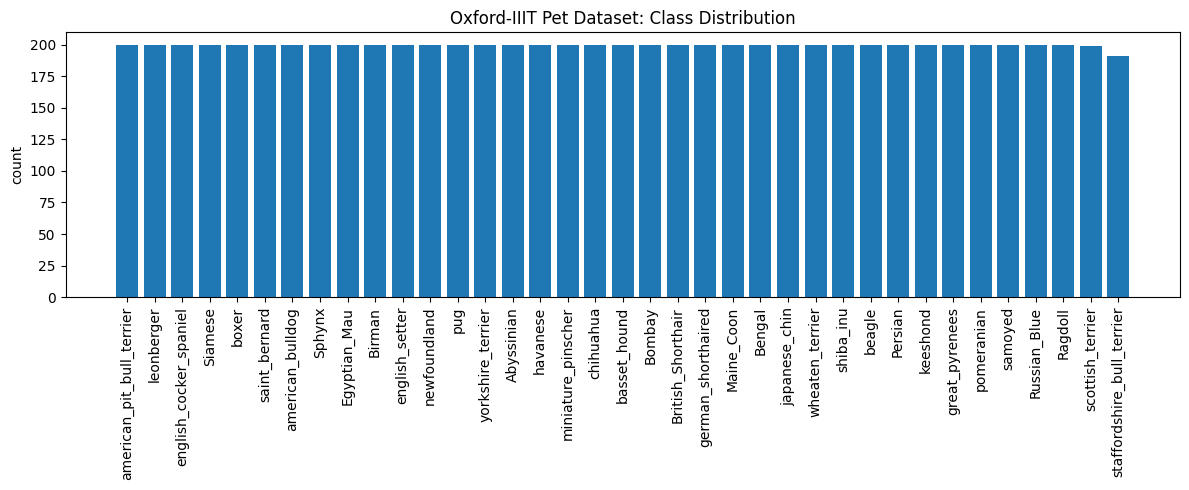

In [ ]:
plt.figure(figsize=(12, 5))
plt.bar(df_counts["class"], df_counts["train"])
plt.title("Oxford-IIIT Pet Dataset: Class Distribution")
plt.xticks(rotation=90)
plt.ylabel("count")
plt.tight_layout()
plt.show()

Show sample images (classification)

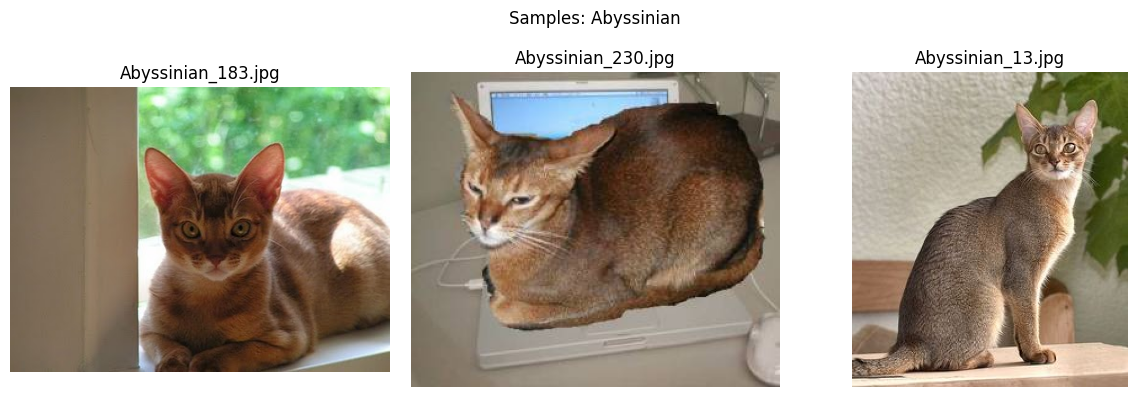

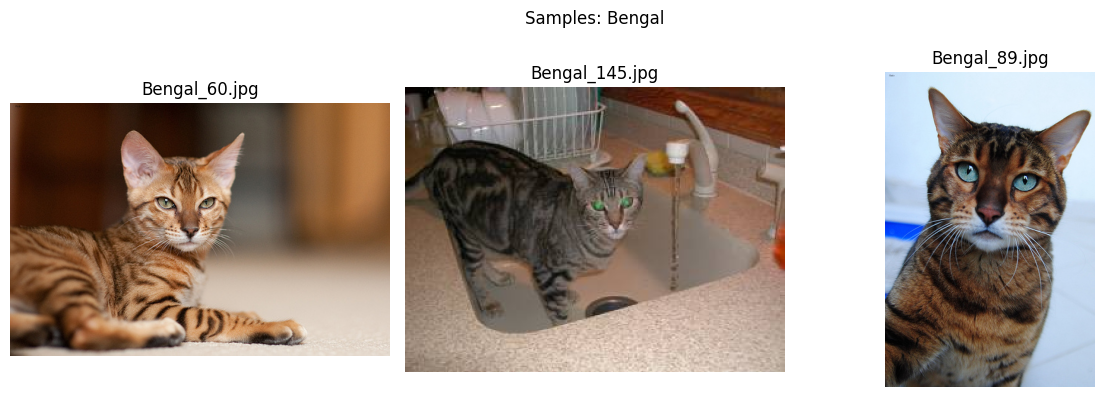

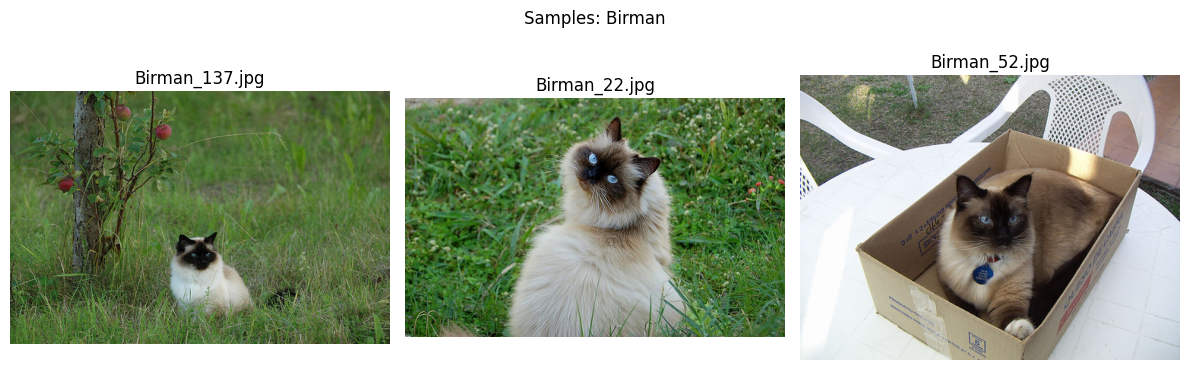

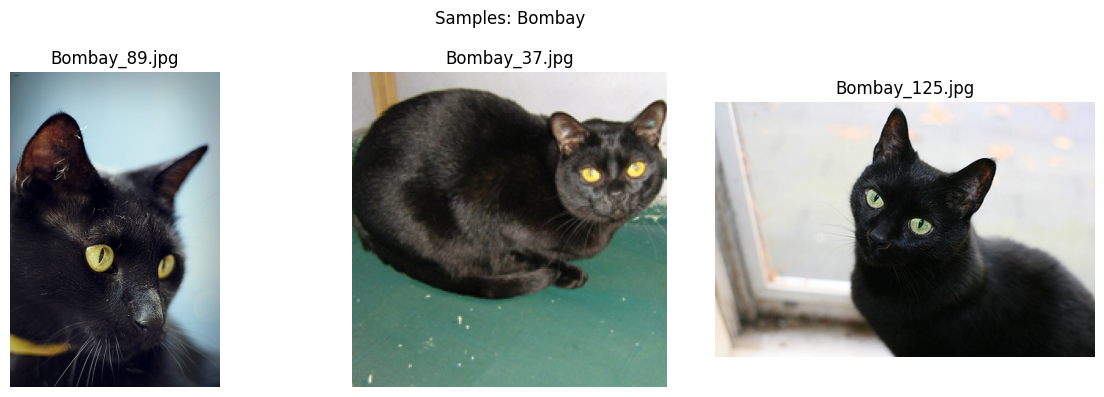

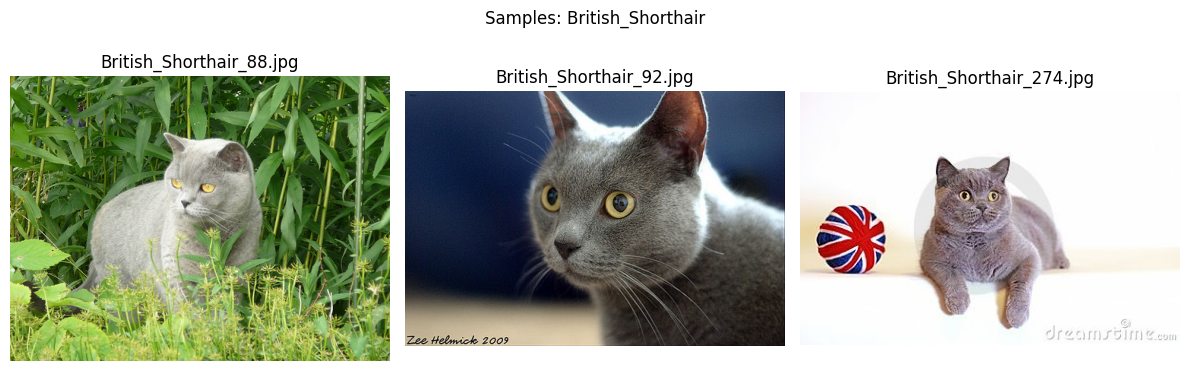

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

def sample_images_from_class(images_dir, class_name, k=9):
    # Filter the flat directory for files belonging to this class
    # Filenames are format: Class_Name_123.jpg
    files = [f for f in os.listdir(images_dir) if f.startswith(f"{class_name}_") and f.lower().endswith((".jpg",".jpeg",".png"))]
    files = random.sample(files, k=min(k, len(files)))
    return [os.path.join(images_dir, f) for f in files]

def show_grid(paths, title="", cols=3):
    n = len(paths)
    if n == 0: return
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(cols*4, rows*4))
    for i, p in enumerate(paths):
        img = Image.open(p).convert("RGB")
        plt.subplot(rows, cols, i+1)
        plt.imshow(img)
        plt.title(os.path.basename(p)[:25])
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Use the actual images directory found in the dataset
images_dir = paths.images_dir
# Preview a few classes to avoid excessive output
for c in classes[:5]:
    imgs = sample_images_from_class(images_dir, c, k=3)
    show_grid(imgs, title=f"Samples: {c}", cols=3)

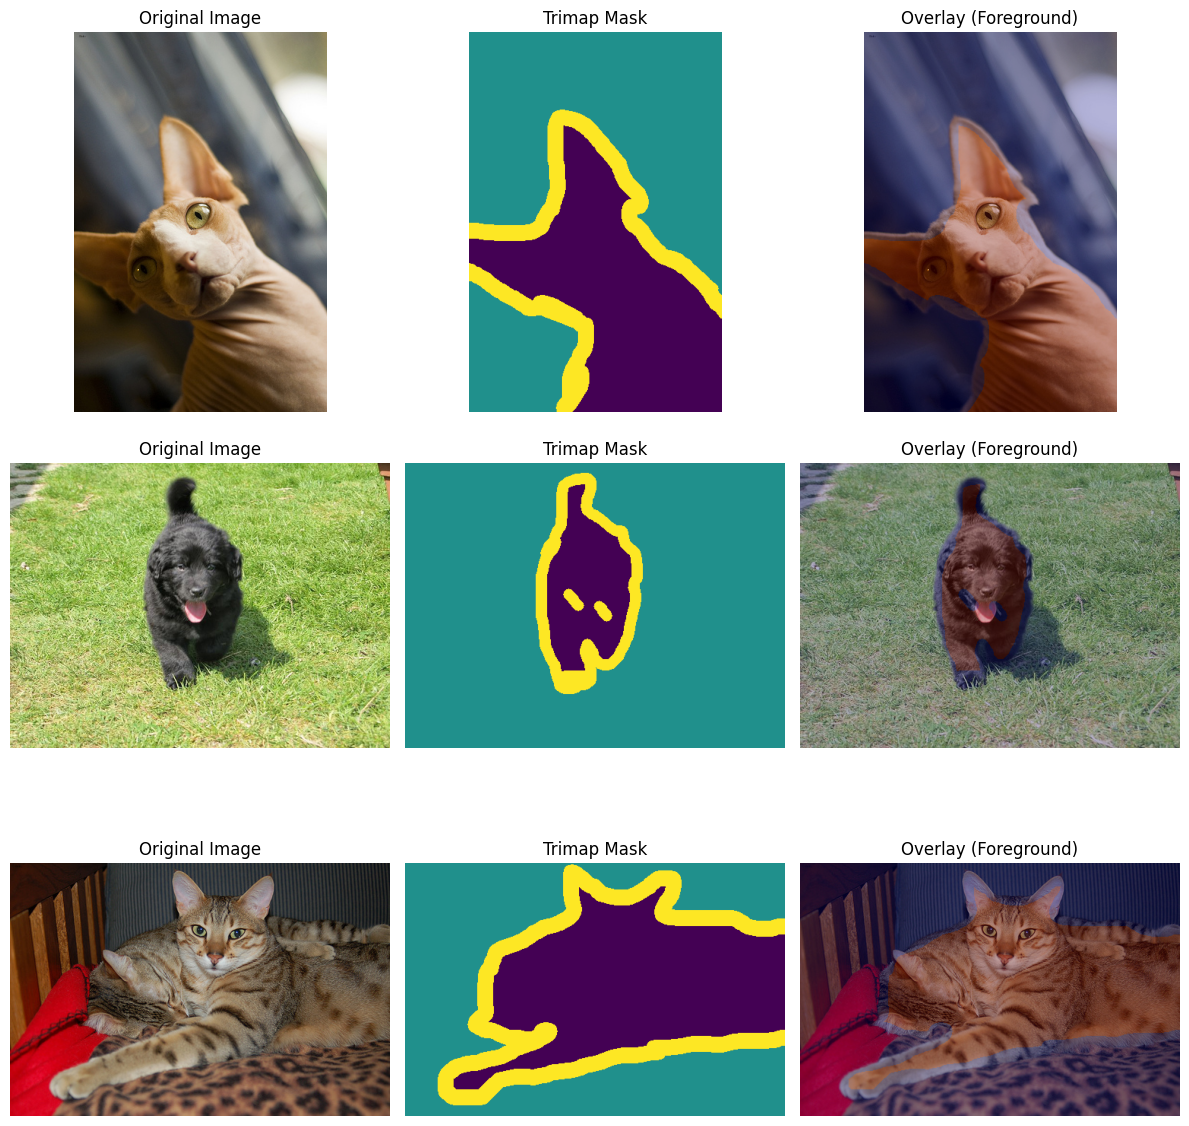

In [ ]:
def show_seg_overlay(paths, k=6, img_size=None):
    img_dir = paths.images_dir
    msk_dir = paths.trimaps_dir

    # Get list of images
    files = [f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    # Sample k random images
    files = random.sample(files, k=min(k, len(files)))

    plt.figure(figsize=(12, 4 * k))
    for i, f in enumerate(files):
        base = os.path.splitext(f)[0]
        ip = os.path.join(img_dir, f)
        # In this dataset, masks are always .png and share the same base name
        mp = os.path.join(msk_dir, base + ".png")

        img = Image.open(ip).convert("RGB")
        # Some images might not have a mask, though most do in this dataset
        msk = Image.open(mp) if os.path.exists(mp) else None

        if img_size is not None:
            img = img.resize(img_size)
            if msk is not None:
                msk = msk.resize(img_size, resample=Image.NEAREST)

        img_np = np.array(img)

        # 1. Original Image
        plt.subplot(k, 3, 3 * i + 1)
        plt.imshow(img_np)
        plt.title("Original Image")
        plt.axis("off")

        # 2. Mask
        plt.subplot(k, 3, 3 * i + 2)
        if msk is None:
            plt.imshow(np.zeros((img_np.shape[0], img_np.shape[1])), cmap="gray")
            plt.title("Mask Missing")
        else:
            # Trimap values: 1: Foreground, 2: Background, 3: Outline
            # We often visualize foreground (1) vs rest
            msk_np = np.array(msk)
            plt.imshow(msk_np, cmap="viridis")
            plt.title("Trimap Mask")
        plt.axis("off")

        # 3. Overlay
        plt.subplot(k, 3, 3 * i + 3)
        plt.imshow(img_np)
        if msk is not None:
            # Create a simple binary mask for visualization
            binary_mask = (np.array(msk) == 1).astype(float)
            plt.imshow(binary_mask, cmap="jet", alpha=0.3)
        plt.title("Overlay (Foreground)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Using the paths object defined in previous cells
show_seg_overlay(paths, k=3)

# Label maps

In [ ]:
@dataclass
class LabelMap:
    labels: List[str]
    label_to_id: Dict[str, int]
    id_to_label: Dict[int, str]

def get_label_map_from_list(class_list: List[str]) -> LabelMap:
    labels = sorted(class_list)
    label_to_id = {lab: i for i, lab in enumerate(labels)}
    id_to_label = {i: lab for lab, i in label_to_id.items()}
    return LabelMap(labels, label_to_id, id_to_label)

# 'classes' was defined in the EDA cells by parsing filenames
label_map = get_label_map_from_list(classes)
print("Total Classes:", len(label_map.labels))
print("Sample Labels:", label_map.labels[:5])

Total Classes: 37
Sample Labels: ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair']


# Dataframe builders and Split

In [ ]:
import os
import pandas as pd
import re
from sklearn.model_selection import train_test_split

def get_class_from_filename(fname):
    match = re.match(r'^(.+)_\d+\.', fname)
    return match.group(1) if match else None

def build_pet_dfs(paths: Paths, val_size=0.2, test_size=0.1, seed=42):
    img_dir = paths.images_dir
    msk_dir = paths.trimaps_dir

    recs = []
    for fname in sorted(os.listdir(img_dir)):
        if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        base = os.path.splitext(fname)[0]
        img_path = os.path.join(img_dir, fname)
        msk_path = os.path.join(msk_dir, base + ".png")

        if not os.path.exists(msk_path):
            continue

        label = get_class_from_filename(fname)
        if label:
            recs.append({"img_path": img_path, "msk_path": msk_path, "label": label})

    df_full = pd.DataFrame(recs)

    # Split into train_val and test
    train_val_df, test_df = train_test_split(
        df_full, test_size=test_size, random_state=seed, stratify=df_full["label"]
    )

    # Split train_val into train and val
    adj_val_size = val_size / (1 - test_size)
    train_df, val_df = train_test_split(
        train_val_df, test_size=adj_val_size, random_state=seed, stratify=train_val_df["label"]
    )

    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

# Building shared dataframes for both tasks
seg_train_df, seg_val_df, seg_df_test = build_pet_dfs(paths)

# Re-using the same splits for classification
cls_train_df, cls_val_df, cls_df_test_labeled = seg_train_df, seg_val_df, seg_df_test

print(f"Segmentation - Train: {len(seg_train_df)}, Val: {len(seg_val_df)}, Test: {len(seg_df_test)}")
print(f"Classification - Train: {len(cls_train_df)}, Val: {len(cls_val_df)}, Test: {len(cls_df_test_labeled)}")

Segmentation - Train: 5173, Val: 1478, Test: 739
Classification - Train: 5173, Val: 1478, Test: 739


# Datasets Pre Processing

In [ ]:
# Enhanced Augmentation for Segmentation
class OxfordPetSegDataset(Dataset):
    def __init__(self, df: pd.DataFrame, img_size=(384, 384), augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["img_path"]).convert("L")
        msk = Image.open(row["msk_path"]).convert("L")

        # Apply same random transforms to both image and mask
        if self.augment:
            if random.random() > 0.5:
                img = TF.hflip(img)
                msk = TF.hflip(msk)

            angle = random.uniform(-20, 20)
            img = TF.rotate(img, angle)
            msk = TF.rotate(msk, angle, interpolation=InterpolationMode.NEAREST)

        img = TF.resize(img, self.img_size, interpolation=InterpolationMode.BILINEAR)
        msk = TF.resize(msk, self.img_size, interpolation=InterpolationMode.NEAREST)

        x = TF.to_tensor(img)
        # Oxford trimaps use 1: foreground, 2: background, 3: outline.
        m_np = np.array(msk)
        binary_mask = (m_np == 1).astype(np.float32)
        y = torch.from_numpy(binary_mask).unsqueeze(0)

        return x, y

class OxfordPetClsDatasetGray(Dataset):
    def __init__(self, df: pd.DataFrame, label_map: LabelMap, img_size=(384, 384), augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.label_map = label_map
        self.img_size = img_size
        self.augment = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        y = self.label_map.label_to_id[row["label"]]
        img = Image.open(row["img_path"]).convert("L")
        img = TF.resize(img, self.img_size, interpolation=InterpolationMode.BILINEAR)

        if self.augment:
            if random.random() < 0.5:
                img = TF.hflip(img)

        x = TF.to_tensor(img)
        return x, torch.tensor(y, dtype=torch.long)

In [ ]:
# Oxford-IIIT Pet dataset classes used by the loaders below
class OxfordPetSegDataset(Dataset):
    def __init__(self, df: pd.DataFrame, img_size=(384, 384), augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["img_path"]).convert("L")
        msk = Image.open(row["msk_path"]).convert("L")

        if self.augment:
            if random.random() < 0.5:
                img = TF.hflip(img)
                msk = TF.hflip(msk)
            if random.random() < 0.5:
                img = TF.vflip(img)
                msk = TF.vflip(msk)

        img = TF.resize(img, self.img_size, interpolation=InterpolationMode.BILINEAR)
        msk = TF.resize(msk, self.img_size, interpolation=InterpolationMode.NEAREST)

        x = TF.to_tensor(img)
        m_np = np.array(msk)
        binary_mask = (m_np == 1).astype(np.float32)
        y = torch.from_numpy(binary_mask).unsqueeze(0)
        return x, y

class OxfordPetClsDatasetGray(Dataset):
    def __init__(self, df: pd.DataFrame, label_map: LabelMap, img_size=(384, 384), augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.label_map = label_map
        self.img_size = img_size
        self.augment = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        y = self.label_map.label_to_id[row["label"]]
        img = Image.open(row["img_path"]).convert("L")
        img = TF.resize(img, self.img_size, interpolation=InterpolationMode.BILINEAR)

        if self.augment:
            if random.random() < 0.5:
                img = TF.hflip(img)

        x = TF.to_tensor(img)
        return x, torch.tensor(y, dtype=torch.long)

In [ ]:
SEG_IMG_SIZE = (384, 384)
CLS_IMG_SIZE = (384, 384)

# Re-initializing with fixed dataset class
seg_train_loader = DataLoader(OxfordPetSegDataset(seg_train_df, SEG_IMG_SIZE, augment=True),
                              batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
seg_val_loader = DataLoader(OxfordPetSegDataset(seg_val_df, SEG_IMG_SIZE, augment=False),
                            batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
seg_test_loader = DataLoader(OxfordPetSegDataset(seg_df_test, SEG_IMG_SIZE, augment=False),
                             batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

cls_train_loader = DataLoader(OxfordPetClsDatasetGray(cls_train_df, label_map, CLS_IMG_SIZE, augment=True),
                              batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
cls_val_loader = DataLoader(OxfordPetClsDatasetGray(cls_val_df, label_map, CLS_IMG_SIZE, augment=False),
                            batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
cls_test_loader = DataLoader(OxfordPetClsDatasetGray(cls_df_test_labeled, label_map, CLS_IMG_SIZE, augment=False),
                             batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

print("Loaders refreshed with Oxford-IIIT Pet dataset classes.")

Loaders refreshed with Oxford-IIIT Pet dataset classes.


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Mask batch shape: torch.Size([8, 1, 384, 384])
Unique values in a sample mask: tensor([0., 1.])


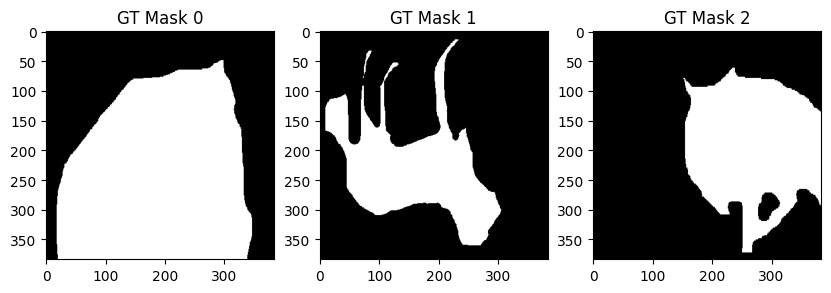

In [ ]:
# Debug: Check if masks are binary or constant
sample_batch_x, sample_batch_y = next(iter(seg_train_loader))
print(f"Mask batch shape: {sample_batch_y.shape}")
print(f"Unique values in a sample mask: {torch.unique(sample_batch_y[0])}")

# Visualize a few with explicit range to ensure they aren't 'black'
plt.figure(figsize=(10, 4))
for i in range(min(3, len(sample_batch_y))):
    plt.subplot(1, 3, i+1)
    # Using vmin/vmax ensures 0 is black and 1 is white regardless of content
    plt.imshow(sample_batch_y[i].squeeze(), cmap='gray', vmin=0, vmax=1)
    plt.title(f"GT Mask {i}")
plt.show()

In [ ]:
# Enhanced Augmentation for Segmentation
class OxfordPetSegDataset(Dataset):
    def __init__(self, df: pd.DataFrame, img_size=(384, 384), augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["img_path"]).convert("L")
        msk = Image.open(row["msk_path"]).convert("L")

        if self.augment:
            # Apply same random transforms to both image and mask
            if random.random() > 0.5:
                img = TF.hflip(img)
                msk = TF.hflip(msk)

            angle = random.uniform(-20, 20)
            img = TF.rotate(img, angle)
            msk = TF.rotate(msk, angle, interpolation=InterpolationMode.NEAREST)

        img = TF.resize(img, self.img_size, interpolation=InterpolationMode.BILINEAR)
        msk = TF.resize(msk, self.img_size, interpolation=InterpolationMode.NEAREST)

        x = TF.to_tensor(img)
        # Ensure mask is 0 or 1. The Oxford trimaps use 1:FG, 2:BG, 3:Outline.
        # Let's treat 1 (Foreground) as our target.
        m_np = np.array(msk)
        binary_mask = (m_np == 1).astype(np.float32)
        y = torch.from_numpy(binary_mask).unsqueeze(0)

        return x, y

class OxfordPetClsDatasetGray(Dataset):
    def __init__(self, df: pd.DataFrame, label_map: LabelMap, img_size=(384, 384), augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.label_map = label_map
        self.img_size = img_size
        self.augment = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        y = self.label_map.label_to_id[row["label"]]
        img = Image.open(row["img_path"]).convert("L")
        img = TF.resize(img, self.img_size, interpolation=InterpolationMode.BILINEAR)

        if self.augment:
            if random.random() < 0.5: img = TF.hflip(img)

        x = TF.to_tensor(img)
        return x, torch.tensor(y, dtype=torch.long)

# Models

U-Net

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base*8, base*16)

        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2)
        self.dec4 = DoubleConv(base*16, base*8)
        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.dec3 = DoubleConv(base*8, base*4)
        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.dec2 = DoubleConv(base*4, base*2)
        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.dec1 = DoubleConv(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        d4 = self.up4(b); d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4); d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3); d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2); d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)

Att U net

In [ ]:
class AttentionGate(nn.Module):
    def __init__(self, F_g: int, F_l: int, F_int: int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, g):
        psi = self.relu(self.W_g(g) + self.W_x(x))
        alpha = self.psi(psi)
        return x * alpha

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base*8, base*16)

        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2)
        self.att4 = AttentionGate(base*8, base*8, base*4)
        self.dec4 = DoubleConv(base*16, base*8)

        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.att3 = AttentionGate(base*4, base*4, base*2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.att2 = AttentionGate(base*2, base*2, base)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.att1 = AttentionGate(base, base, max(1, base//2))
        self.dec1 = DoubleConv(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        d4 = self.up4(b); e4a = self.att4(e4, d4); d4 = self.dec4(torch.cat([d4, e4a], dim=1))
        d3 = self.up3(d4); e3a = self.att3(e3, d3); d3 = self.dec3(torch.cat([d3, e3a], dim=1))
        d2 = self.up2(d3); e2a = self.att2(e2, d2); d2 = self.dec2(torch.cat([d2, e2a], dim=1))
        d1 = self.up1(d2); e1a = self.att1(e1, d1); d1 = self.dec1(torch.cat([d1, e1a], dim=1))
        return self.out(d1)

Classifier head

In [ ]:
class UNetEncoder(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base*8, base*16)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))
        return b

class EncoderClassifier(nn.Module):
    def __init__(self, encoder: nn.Module, feat_ch: int, num_classes: int):
        super().__init__()
        self.encoder = encoder
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(feat_ch, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        feat = self.encoder(x)
        feat = self.gap(feat)
        return self.head(feat)

# Losses + Metrics

In [ ]:
BCE = nn.BCEWithLogitsLoss()
CE  = nn.CrossEntropyLoss()

def dice_loss_soft(logits: torch.Tensor, targets: torch.Tensor, eps: float = 1e-7) -> torch.Tensor:
    probs = torch.sigmoid(logits)
    p = probs.view(probs.size(0), -1)
    t = targets.view(targets.size(0), -1)
    inter = (p * t).sum(dim=1)
    dice = (2 * inter + eps) / (p.sum(dim=1) + t.sum(dim=1) + eps)
    return 1 - dice.mean()
# total segmentation loss
def seg_loss_fn(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    return BCE(logits, targets) + dice_loss_soft(logits, targets)

@torch.no_grad()
def seg_confusion_from_logits(logits: torch.Tensor, targets: torch.Tensor, thr: float = 0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > thr).float()
    p = preds.view(-1)
    t = targets.view(-1)
    tp = (p * t).sum().item()
    fp = (p * (1 - t)).sum().item()
    fn = ((1 - p) * t).sum().item()
    tn = ((1 - p) * (1 - t)).sum().item()
    return tp, fp, fn, tn

def seg_metrics_from_confusion(tp, fp, fn, tn, eps: float = 1e-7):
    iou_fg = (tp + eps) / (tp + fp + fn + eps)
    iou_bg = (tn + eps) / (tn + fn + fp + eps)
    miou = 0.5 * (iou_fg + iou_bg)
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    pixacc = (tp + tn + eps) / (tp + tn + fp + fn + eps)
    return float(miou), float(dice), float(pixacc)

def cls_metrics_from_confmat(cm: np.ndarray, eps: float = 1e-9):
    tp = np.diag(cm).astype(np.float64)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    prec = (tp + eps) / (tp + fp + eps)
    rec  = (tp + eps) / (tp + fn + eps)
    f1   = (2 * prec * rec + eps) / (prec + rec + eps)
    acc  = float(tp.sum() / (cm.sum() + eps))
    return acc, float(prec.mean()), float(rec.mean()), float(f1.mean())


# Train/Eval Loops

Train/Eval loops (Seg)

In [ ]:
def train_seg_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer):
    model.train()
    total_loss, n = 0.0, 0
    tp = fp = fn = tn = 0.0

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with AUT():
            logits = model(x)
            loss = seg_loss_fn(logits, y)

        SCALER.scale(loss).backward()
        SCALER.step(optimizer)
        SCALER.update()

        total_loss += float(loss.item()); n += 1
        a, b, c, d = seg_confusion_from_logits(logits.detach(), y)
        tp += a; fp += b; fn += c; tn += d

    miou, dice, pix = seg_metrics_from_confusion(tp, fp, fn, tn)
    return total_loss / max(1, n), miou, dice, pix

@torch.no_grad()
def eval_seg(model: nn.Module, loader: DataLoader):
    model.eval()
    total_loss, n = 0.0, 0
    tp = fp = fn = tn = 0.0

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        with AUT():
            logits = model(x)
            loss = seg_loss_fn(logits, y)

        total_loss += float(loss.item()); n += 1
        a, b, c, d = seg_confusion_from_logits(logits, y)
        tp += a; fp += b; fn += c; tn += d

    miou, dice, pix = seg_metrics_from_confusion(tp, fp, fn, tn)
    return total_loss / max(1, n), miou, dice, pix


Train/Eval loops (Cls)

In [ ]:
def train_cls_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer, num_classes: int):
    model.train()
    if hasattr(model, "encoder"):
        model.encoder.eval()

    total_loss, n = 0.0, 0
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = CE(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += float(loss.item()); n += 1
        preds = logits.argmax(dim=1).detach().cpu().numpy()
        trues = y.detach().cpu().numpy()
        for t, p in zip(trues, preds):
            cm[t, p] += 1

    acc, mp, mr, mf1 = cls_metrics_from_confmat(cm)
    return total_loss / max(1, n), acc, mp, mr, mf1

@torch.no_grad()
def eval_cls(model: nn.Module, loader: DataLoader, num_classes: int):
    model.eval()
    total_loss, n = 0.0, 0
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        loss = CE(logits, y)

        total_loss += float(loss.item()); n += 1
        preds = logits.argmax(dim=1).detach().cpu().numpy()
        trues = y.detach().cpu().numpy()
        for t, p in zip(trues, preds):
            cm[t, p] += 1

    acc, mp, mr, mf1 = cls_metrics_from_confmat(cm)
    return total_loss / max(1, n), acc, mp, mr, mf1


# Training

Stage-1 Segmentation Training (U-Net)

In [ ]:
import torch
import os

# Path to your previously trained weights
weights_path = '/content/stage1_unet_seg_best.pth'

# 1. Re-initialize the model architecture
# Ensure the parameters (in_ch, out_ch, base) match your original training
seg_model = UNet(in_ch=1, out_ch=1, base=32).to(DEVICE)

# 2. Load the state dictionary
if os.path.exists(weights_path):
    state_dict = torch.load(weights_path, map_location=DEVICE)
    # If the checkpoint was saved as a full dict containing 'model_state_dict', extract it
    if isinstance(state_dict, dict) and 'model_state_dict' in state_dict:
        state_dict = state_dict['model_state_dict']

    seg_model.load_state_dict(state_dict)
    print(f'Successfully loaded trained parameters from: {weights_path}')
else:
    print(f'File not found at: {weights_path}')

seg_model.eval()

File not found at: /content/stage1_unet_seg_best.pth


UNet(
  (enc1): DoubleConv(
    (net): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (net): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (net): Sequential(


In [ ]:
MODEL_TYPE = "unet"
EPOCHS = 20
LR = 1e-3
PATIENCE = 7

# Create output directory if it doesn't exist
os.makedirs(paths.out_dir, exist_ok=True)

if MODEL_TYPE == "unet":
    seg_model = UNet(in_ch=1, out_ch=1, base=32).to(DEVICE)
    seg_ckpt_path = os.path.join(paths.out_dir, "stage1_unet_seg_best.pth")
    seg_final_ckpt_path = os.path.join(paths.out_dir, "stage1_unet_seg_final.pth")
else:
    seg_model = AttentionUNet(in_ch=1, out_ch=1, base=32).to(DEVICE)
    seg_ckpt_path = os.path.join(paths.out_dir, "stage1_attunet_seg_best.pth")
    seg_final_ckpt_path = os.path.join(paths.out_dir, "stage1_attunet_seg_final.pth")

optimizer = torch.optim.Adam(seg_model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

best_val_dice = -1.0
no_improve = 0
hist = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_miou, tr_dice, _ = train_seg_one_epoch(seg_model, seg_train_loader, optimizer)
    va_loss, va_miou, va_dice, _ = eval_seg(seg_model, seg_val_loader)
    scheduler.step(va_dice)

    hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss)
    hist["train_dice"].append(tr_dice); hist["val_dice"].append(va_dice)

    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:02d}/{EPOCHS} | lr={lr_now:.2e} | "
          f"loss {tr_loss:.4f}/{va_loss:.4f} | dice {tr_dice:.4f}/{va_dice:.4f} | miou {tr_miou:.4f}/{va_miou:.4f}")

    if va_dice > best_val_dice + 1e-4:
        best_val_dice = va_dice
        no_improve = 0
        torch.save(seg_model.state_dict(), seg_ckpt_path)
        print(f"Saved best: {seg_ckpt_path} (val_dice={best_val_dice:.4f})")
    else:
        no_improve += 1

    if no_improve >= PATIENCE:
        print("Early stopping.")
        break

# Save final checkpoint after all epochs
torch.save({
    "model_state_dict": seg_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epoch,
    "history": hist,
    "best_val_dice": best_val_dice,
    "model_type": MODEL_TYPE,
}, seg_final_ckpt_path)
print(f"Saved final checkpoint: {seg_final_ckpt_path}")
print("Saved files in output folder:", os.listdir(paths.out_dir))

# Load best checkpoint + summarize
seg_model.load_state_dict(torch.load(seg_ckpt_path, map_location=DEVICE))
tr = eval_seg(seg_model, seg_train_loader)
va = eval_seg(seg_model, seg_val_loader)
te = eval_seg(seg_model, seg_test_loader)

seg_summary = pd.DataFrame(
    [["train", *tr], ["val", *va], ["test", *te]],
    columns=["split", "loss", "mIoU", "dice", "pixel_accuracy"],
)
print("\n=== Stage-1 Summary ===")
print(seg_summary.to_string(index=False))

# Save full model weights
torch.save(seg_model.state_dict(), os.path.join(paths.out_dir, 'unet_base_full.pth'))

# Save encoder sub-weights separately (for use in Stage-2 frozen encoder)
encoder_state = {k: v for k, v in seg_model.state_dict().items()
                 if k.startswith(('enc1', 'enc2', 'enc3', 'enc4', 'bottleneck'))}
torch.save(encoder_state, os.path.join(paths.out_dir, 'encoder_base.pth'))

print("Base U-Net weights saved!")

Epoch 01/20 | lr=1.00e-03 | loss 1.0774/1.4437 | dice 0.5710/0.6464 | miou 0.5256/0.5440
Saved best: /kaggle/working/stage1_unet_seg_best.pth (val_dice=0.6464)
Epoch 02/20 | lr=1.00e-03 | loss 0.8408/0.8980 | dice 0.6876/0.6876 | miou 0.6436/0.6156
Saved best: /kaggle/working/stage1_unet_seg_best.pth (val_dice=0.6876)
Epoch 03/20 | lr=1.00e-03 | loss 0.7199/0.7177 | dice 0.7405/0.7453 | miou 0.6934/0.6992
Saved best: /kaggle/working/stage1_unet_seg_best.pth (val_dice=0.7453)
Epoch 04/20 | lr=1.00e-03 | loss 0.6580/0.5877 | dice 0.7659/0.7918 | miou 0.7185/0.7446
Saved best: /kaggle/working/stage1_unet_seg_best.pth (val_dice=0.7918)
Epoch 05/20 | lr=1.00e-03 | loss 0.6128/0.5846 | dice 0.7835/0.7976 | miou 0.7365/0.7472
Saved best: /kaggle/working/stage1_unet_seg_best.pth (val_dice=0.7976)
Epoch 06/20 | lr=1.00e-03 | loss 0.5812/0.5586 | dice 0.7961/0.8005 | miou 0.7497/0.7588
Saved best: /kaggle/working/stage1_unet_seg_best.pth (val_dice=0.8005)
Epoch 07/20 | lr=1.00e-03 | loss 0.5397/

Plot Stage-1 curves

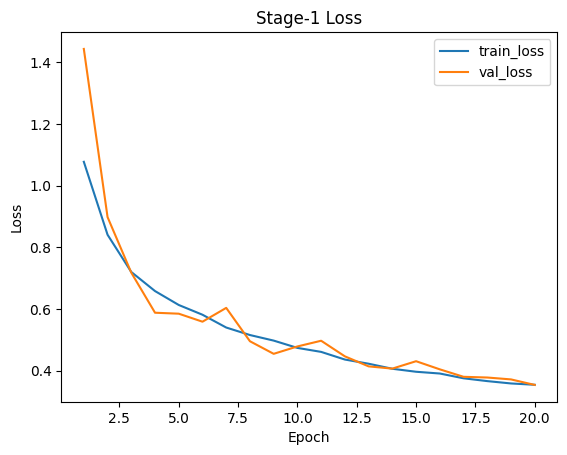

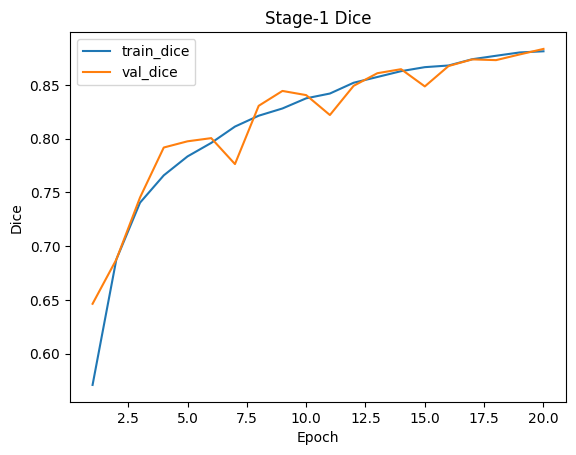

In [ ]:
ep = np.arange(1, len(hist["train_loss"]) + 1)

plt.figure()
plt.plot(ep, hist["train_loss"], label="train_loss")
plt.plot(ep, hist["val_loss"], label="val_loss")
plt.title("Stage-1 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure()
plt.plot(ep, hist["train_dice"], label="train_dice")
plt.plot(ep, hist["val_dice"], label="val_dice")
plt.title("Stage-1 Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.legend()
plt.show()


Stage-1 Segmentation Training (Attention U-Net)

In [ ]:
MODEL_TYPE = "attunet"
EPOCHS = 20
LR = 1e-3
PATIENCE = 7

if MODEL_TYPE == "unet":
    seg_model = UNet(in_ch=1, out_ch=1, base=32).to(DEVICE)
    seg_ckpt_path = os.path.join(paths.out_dir, "stage1_unet_seg_best.pth")
    seg_final_ckpt_path = os.path.join(paths.out_dir, "stage1_unet_seg_final.pth")
else:
    seg_model = AttentionUNet(in_ch=1, out_ch=1, base=32).to(DEVICE)
    seg_ckpt_path = os.path.join(paths.out_dir, "stage1_attunet_seg_best.pth")
    seg_final_ckpt_path = os.path.join(paths.out_dir, "stage1_attunet_seg_final.pth")

optimizer = torch.optim.Adam(seg_model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

best_val_dice = -1.0
no_improve = 0
hist = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_miou, tr_dice, _ = train_seg_one_epoch(seg_model, seg_train_loader, optimizer)
    va_loss, va_miou, va_dice, _ = eval_seg(seg_model, seg_val_loader)
    scheduler.step(va_dice)

    hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss)
    hist["train_dice"].append(tr_dice); hist["val_dice"].append(va_dice)

    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:02d}/{EPOCHS} | lr={lr_now:.2e} | "
          f"loss {tr_loss:.4f}/{va_loss:.4f} | dice {tr_dice:.4f}/{va_dice:.4f} | miou {tr_miou:.4f}/{va_miou:.4f}")

    if va_dice > best_val_dice + 1e-4:
        best_val_dice = va_dice
        no_improve = 0
        torch.save(seg_model.state_dict(), seg_ckpt_path)
        print(f" Saved best: {seg_ckpt_path} (val_dice={best_val_dice:.4f})")
    else:
        no_improve += 1

    if no_improve >= PATIENCE:
        print("Early stopping.")
        break

# Save final checkpoint after all epochs
torch.save({
    "model_state_dict": seg_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epoch,
    "history": hist,
    "best_val_dice": best_val_dice,
    "model_type": MODEL_TYPE,
}, seg_final_ckpt_path)
print(f"Saved final checkpoint: {seg_final_ckpt_path}")

# Load best + summarize
seg_model.load_state_dict(torch.load(seg_ckpt_path, map_location=DEVICE))
tr = eval_seg(seg_model, seg_train_loader)
va = eval_seg(seg_model, seg_val_loader)
te = eval_seg(seg_model, seg_test_loader)

seg_summary = pd.DataFrame(
    [["train", *tr], ["val", *va], ["test", *te]],
    columns=["split", "loss", "mIoU", "dice", "pixel_accuracy"],
)
print("\n=== Stage-1 Summary ===")
print(seg_summary.to_string(index=False))

Epoch 01/20 | lr=1.00e-03 | loss 1.0624/0.9080 | dice 0.5773/0.6693 | miou 0.5352/0.6142
 Saved best: /kaggle/working/stage1_attunet_seg_best.pth (val_dice=0.6693)
Epoch 02/20 | lr=1.00e-03 | loss 0.8651/1.0166 | dice 0.6778/0.6982 | miou 0.6334/0.6226
 Saved best: /kaggle/working/stage1_attunet_seg_best.pth (val_dice=0.6982)
Epoch 03/20 | lr=1.00e-03 | loss 0.7113/0.9418 | dice 0.7438/0.7293 | miou 0.6970/0.6486
 Saved best: /kaggle/working/stage1_attunet_seg_best.pth (val_dice=0.7293)
Epoch 04/20 | lr=1.00e-03 | loss 0.6124/0.5519 | dice 0.7830/0.8117 | miou 0.7364/0.7651
 Saved best: /kaggle/working/stage1_attunet_seg_best.pth (val_dice=0.8117)
Epoch 05/20 | lr=1.00e-03 | loss 0.5603/0.6815 | dice 0.8036/0.7627 | miou 0.7579/0.7033
Epoch 06/20 | lr=1.00e-03 | loss 0.5304/0.4703 | dice 0.8157/0.8399 | miou 0.7712/0.7956
 Saved best: /kaggle/working/stage1_attunet_seg_best.pth (val_dice=0.8399)
Epoch 07/20 | lr=1.00e-03 | loss 0.5067/0.4797 | dice 0.8248/0.8336 | miou 0.7810/0.7899
Ep

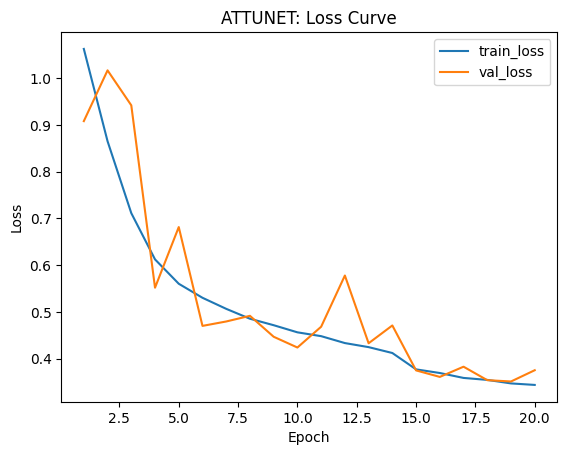

In [ ]:
ep = np.arange(1, len(hist["train_loss"]) + 1)

plt.figure()
plt.plot(ep, hist["train_loss"], label="train_loss")
plt.plot(ep, hist["val_loss"], label="val_loss")
plt.title(f"{MODEL_TYPE.upper()}: Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
CODE_TO_LABEL = {
    "ab": "Abyssinian", "be": "Bengal", "bi": "Birman", "bo": "Bombay",
    "br": "British_Shorthair", "eg": "Egyptian_Mau", "ma": "Maine_Coon", "pe": "Persian",
    "ra": "Ragdoll", "ru": "Russian_Blue", "si": "Siamese", "sp": "Sphynx",
    "ab2": "american_bulldog", "ap": "american_pit_bull_terrier", "ba": "basset_hound",
    "bea": "beagle", "bx": "boxer", "ch": "chihuahua", "ec": "english_cocker_spaniel",
    "es": "english_setter", "gs": "german_shorthaired", "gp": "great_pyrenees",
    "hav": "havanese", "jc": "japanese_chin", "ke": "keeshond", "le": "leonberger",
    "mp": "miniature_pinscher", "nf": "newfoundland", "pom": "pomeranian", "pug": "pug",
    "sb": "saint_bernard", "sam": "samoyed", "sc": "scottish_terrier",
    "sh": "shiba_inu", "st": "staffordshire_bull_terrier",
    "wt": "wheaten_terrier", "yo": "yorkshire_terrier"
}

def infer_true_label(image_path: str):
    # Case 1: from classification folder name
    parts = image_path.replace("\\", "/").split("/")
    if "classification_task" in parts:
        i = parts.index("classification_task")
        if i + 2 < len(parts):
            split = parts[i + 1]
            lab   = parts[i + 2]
            if split in ("train", "test"):
                return lab

    # Case 2: from segmentation filename code
    fname = os.path.basename(image_path)
    toks = fname.split("_")
    if len(toks) >= 4:
        code = toks[3].lower()
        return CODE_TO_LABEL.get(code, None)

    return None

def find_gt_mask(image_path: str, data_root: str):
    base = os.path.splitext(os.path.basename(image_path))[0] + ".png"
    candidates = [
        os.path.join(data_root, "segmentation_task/train/masks", base),
        os.path.join(data_root, "segmentation_task/test/masks", base),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    return None

@torch.no_grad()
def demo_project_inference(
    image_path: str,
    seg_model,
    cls_model=None,
    label_map=None,
    img_size=(384, 384),
    thr=0.5,
    data_root=paths.data_root,
):
    seg_model.eval()
    if cls_model is not None:
        cls_model.eval()
    device = next(seg_model.parameters()).device

    # --- Load image + "processed" (resize) ---
    img_orig = Image.open(image_path).convert("L")
    img_proc = TF.resize(img_orig, img_size, interpolation=InterpolationMode.BILINEAR)
    x = TF.to_tensor(img_proc).unsqueeze(0).to(device)

    # --- GT mask (if exists) ---
    mask_path = find_gt_mask(image_path, data_root)
    gt_mask = None
    if mask_path is not None:
        m = Image.open(mask_path).convert("L")
        m = TF.resize(m, img_size, interpolation=InterpolationMode.NEAREST)
        gt_mask = (np.array(m) > 0).astype(np.float32)

    # --- Seg prediction ---
    seg_logits = seg_model(x)
    seg_prob = torch.sigmoid(seg_logits)[0, 0].detach().cpu().numpy()
    pred_mask = (seg_prob > thr).astype(np.float32)

    # --- IoU (foreground) ---
    iou = None
    if gt_mask is not None:
        tp = (pred_mask * gt_mask).sum()
        fp = (pred_mask * (1 - gt_mask)).sum()
        fn = ((1 - pred_mask) * gt_mask).sum()
        eps = 1e-7
        iou = float((tp + eps) / (tp + fp + fn + eps))

    # --- Classification prediction + single-image accuracy (if GT label known) ---
    pred_label = "N/A"
    pred_conf = 0.0
    if cls_model is not None and label_map is not None:
        cls_logits = cls_model(x)
        probs = torch.softmax(cls_logits, dim=1)[0].detach().cpu().numpy()
        pred_id = int(np.argmax(probs))
        pred_label = label_map.id_to_label[pred_id]
        pred_conf = float(probs[pred_id])

    true_label = infer_true_label(image_path)
    cls_acc = None
    if true_label is not None and cls_model is not None:
        cls_acc = 1.0 if pred_label == true_label else 0.0

    # --- Plot
    img_np = np.array(img_proc)
    fig, ax = plt.subplots(2, 3, figsize=(14, 8))

    ax[0, 0].imshow(img_np, cmap="gray"); ax[0, 0].set_title("Original image"); ax[0, 0].axis("off")

    if gt_mask is None:
        ax[0, 1].imshow(np.zeros_like(img_np), cmap="gray")
    else:
        ax[0, 1].imshow(gt_mask, cmap="jet")
    ax[0, 1].set_title("Original mask"); ax[0, 1].axis("off")

    ax[0, 2].imshow(img_np, cmap="gray")
    if gt_mask is not None:
        ax[0, 2].imshow(gt_mask, cmap="jet", alpha=0.35)
    ax[0, 2].set_title("Original image with mask overlay"); ax[0, 2].axis("off")

    ax[1, 0].imshow(img_np, cmap="gray")
    ax[1, 0].set_title("Processed image ")
    ax[1, 0].axis("off")

    ax[1, 1].imshow(pred_mask, cmap="jet"); ax[1, 1].set_title("Predicted mask"); ax[1, 1].axis("off")

    ax[1, 2].imshow(img_np, cmap="gray")
    ax[1, 2].imshow(pred_mask, cmap="jet", alpha=0.35)
    ax[1, 2].set_title("Original image with predicted mask overlay"); ax[1, 2].axis("off")

    # --- Top text includes GIVEN & PREDICTED (what you asked) ---
    given_txt = "N/A" if true_label is None else true_label
    pred_txt = f"{pred_label} ({pred_conf:.2f})"
    acc_txt = "N/A" if cls_acc is None else f"{cls_acc:.2f}"
    iou_txt = "N/A" if iou is None else f"{iou:.3f}"

    fig.suptitle(
        f"given: {given_txt}   predicted: {pred_txt}   classification accuracy - {acc_txt}   IoU - {iou_txt}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

# Inference

Picking a random test image

Random demo image: /kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/images/saint_bernard_49.jpg


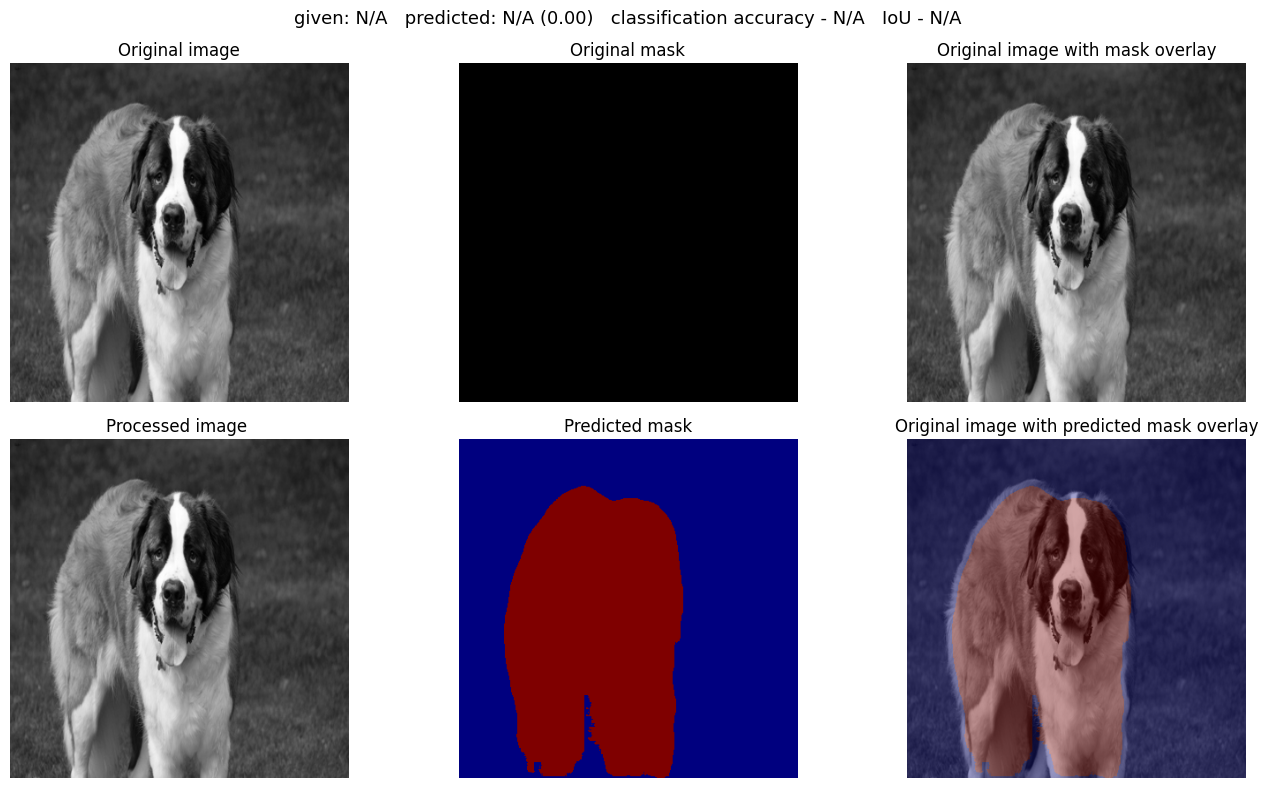

In [ ]:
import random
import os

# Use the paths object defined in previous cells to avoid path errors
IMG_SIZE = (384, 384)

# Get the list of images from the verified images directory
img_dir = paths.images_dir
if os.path.exists(img_dir):
    files = [f for f in os.listdir(img_dir) if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    DEMO_IMAGE_PATH = os.path.join(img_dir, random.choice(files))

    print("Random demo image:", DEMO_IMAGE_PATH)

    # Run inference using the models and label_map defined in previous steps
    demo_project_inference(
        image_path=DEMO_IMAGE_PATH,
        seg_model=seg_model,
        cls_model=globals().get("cls_model"),
        label_map=globals().get("label_map"),
        img_size=IMG_SIZE,
        thr=0.5,
        data_root=paths.data_root
    )
else:
    print(f"Directory not found: {img_dir}. Please ensure the dataset download cell was executed.")

This cell is for giving a image by myself to Inferance

Manual demo image: /kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/images/Bombay_217.jpg


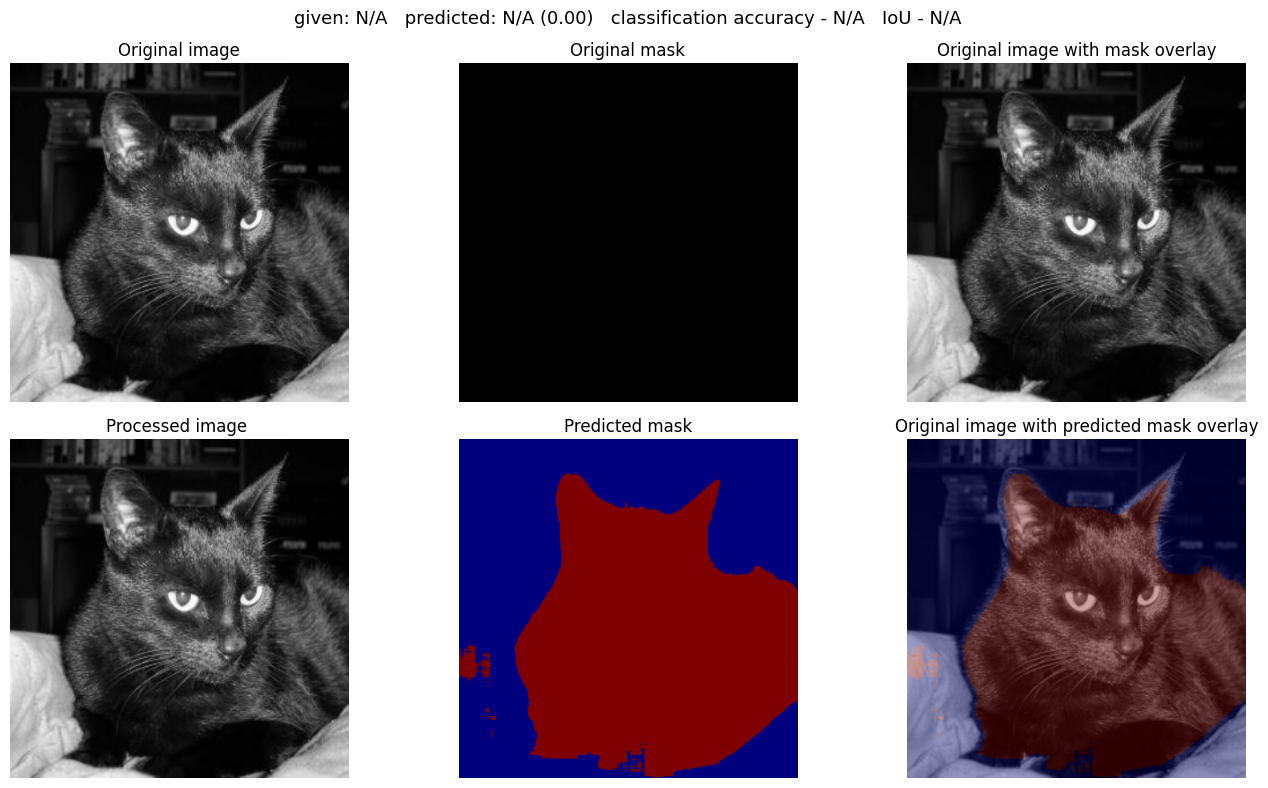

In [ ]:
import os

# Use the dynamic paths defined earlier
DATA_ROOT = paths.data_root
IMG_SIZE = (384, 384)

# Updated to a path that actually exists in your current dataset
# You can change this filename to any other image found in paths.images_dir
DEMO_IMAGE_PATH = os.path.join(paths.images_dir, "Bombay_217.jpg")

print("Manual demo image:", DEMO_IMAGE_PATH)

if os.path.exists(DEMO_IMAGE_PATH):
    demo_project_inference(
        image_path=DEMO_IMAGE_PATH,
        seg_model=seg_model,
        cls_model=globals().get("cls_model"),
        label_map=globals().get("label_map"),
        img_size=IMG_SIZE,
        thr=0.5,
        data_root=DATA_ROOT,
    )
else:
    print(f"File not found: {DEMO_IMAGE_PATH}. Please check the filename.")

Found 2 image(s) in: /kaggle/input/datasets/shakhawatalvi/test-set/Samples

[1/2] Running inference for: /kaggle/input/datasets/shakhawatalvi/test-set/Samples/Sphynx.jpg


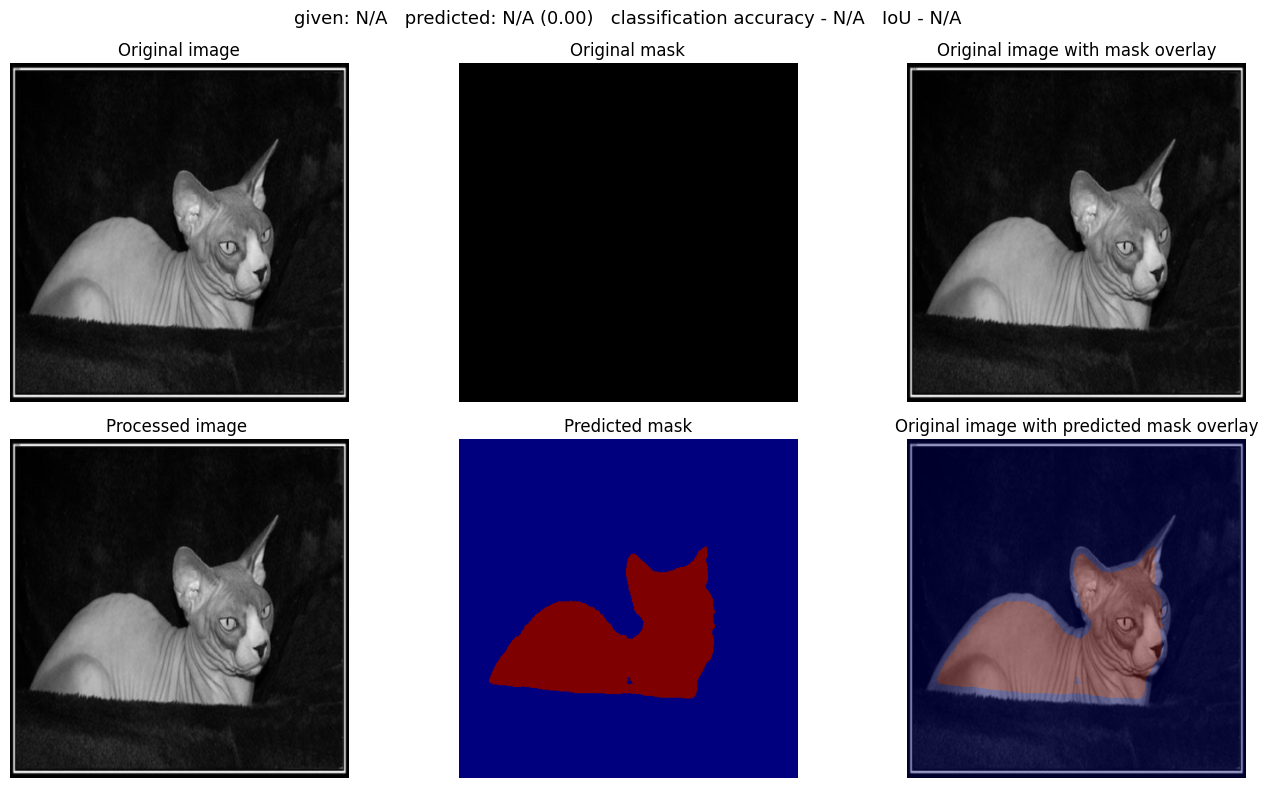


[2/2] Running inference for: /kaggle/input/datasets/shakhawatalvi/test-set/Samples/pug.jpg


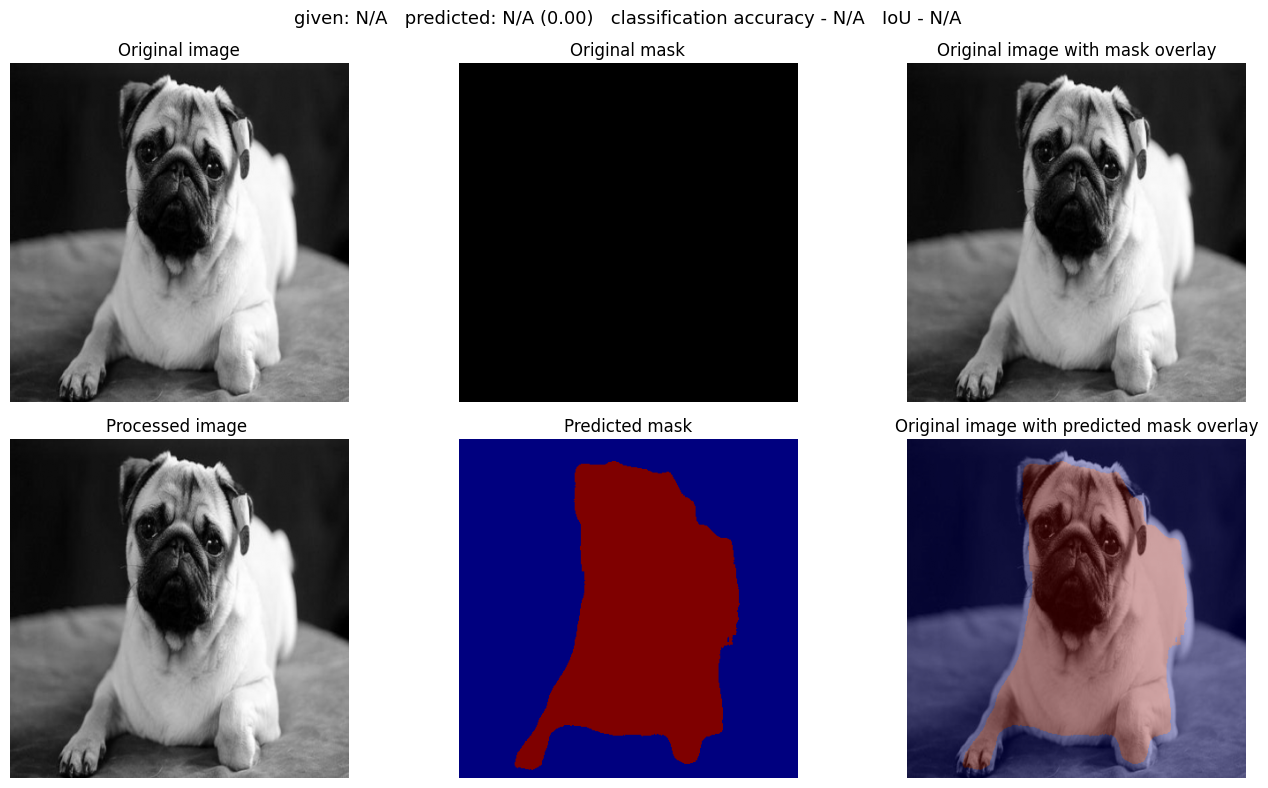

In [ ]:
import os

# Keep these from your notebook
DATA_ROOT = paths.data_root
IMG_SIZE = (384, 384)

# This is a folder containing test images
TEST_DIR = "/kaggle/input/datasets/shakhawatalvi/test-set/Samples"

if not os.path.isdir(TEST_DIR):
    print(f"Folder not found: {TEST_DIR}")
else:
    image_files = sorted(
        f for f in os.listdir(TEST_DIR)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp"))
    )

    print(f"Found {len(image_files)} image(s) in: {TEST_DIR}")

    if len(image_files) == 0:
        print("No image files found in the folder.")
    else:
        for i, fname in enumerate(image_files, start=1):
            image_path = os.path.join(TEST_DIR, fname)
            print(f"\n[{i}/{len(image_files)}] Running inference for: {image_path}")

            demo_project_inference(
                image_path=image_path,
                seg_model=seg_model,
                cls_model=globals().get("cls_model"),
                label_map=globals().get("label_map"),
                img_size=IMG_SIZE,
                thr=0.5,
                data_root=DATA_ROOT,
            )

1. From the section “Open-ended design choices”, analyze how the performance changes
when the segmentation head and the classifier head are trained separately compared to
when they are trained together

Joint training approach

In [ ]:

class DoubleConv(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class MultiTaskUNet(nn.Module):

    def __init__(self, in_ch=1, base=32, num_classes=4):
        super().__init__()
        # ---- Shared encoder ----
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.enc4 = DoubleConv(base * 4, base * 8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 8, base * 16)

        # ---- Segmentation decoder head ----
        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, 2, stride=2)
        self.dec4 = DoubleConv(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)

        self.seg_out = nn.Conv2d(base, 1, 1)  # mask logits

        # ---- Classification head ----
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.cls_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(base * 16, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward_shared(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))
        return e1, e2, e3, e4, b

    def forward_seg(self, x):
        e1, e2, e3, e4, b = self.forward_shared(x)
        d4 = self.up4(b); d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4); d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3); d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2); d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.seg_out(d1)  # mask logits

    def forward_cls(self, x):
        _, _, _, _, b = self.forward_shared(x)
        v = self.gap(b)
        return self.cls_head(v)


In [ ]:
# --- Use existing splits already built in cell eYdtWM-03glE ---
# The dataframes seg_train_df, seg_val_df, and seg_df_test were already created

print("Seg splits:", len(seg_train_df), len(seg_val_df), len(seg_df_test))
print("Cls splits:", len(cls_train_df), len(cls_val_df), len(cls_df_test_labeled))

# --- Loaders ---
IMG_SIZE = (384, 384)

# Note: Using OxfordPetSegDataset for segmentation and OxfordPetClsDatasetGray for classification
seg_train_loader = DataLoader(OxfordPetSegDataset(seg_train_df, IMG_SIZE, augment=True),
                              batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
seg_val_loader   = DataLoader(OxfordPetSegDataset(seg_val_df, IMG_SIZE, augment=False),
                              batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
seg_test_loader  = DataLoader(OxfordPetSegDataset(seg_df_test, IMG_SIZE, augment=False),
                              batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

cls_train_loader = DataLoader(OxfordPetClsDatasetGray(cls_train_df, label_map, IMG_SIZE, augment=True),
                              batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
cls_val_loader   = DataLoader(OxfordPetClsDatasetGray(cls_val_df, label_map, IMG_SIZE, augment=False),
                              batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
cls_test_loader  = DataLoader(OxfordPetClsDatasetGray(cls_df_test_labeled, label_map, IMG_SIZE, augment=False),
                              batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

Seg splits: 5173 1478 739
Cls splits: 5173 1478 739


In [ ]:

# Joint train/eval functions (one optimizer step uses BOTH tasks)

def _cycle_iter(loader):
    it = iter(loader)
    while True:
        try:
            yield next(it)
        except StopIteration:
            it = iter(loader)

def train_joint_one_epoch(model, seg_loader, cls_loader, optimizer, w_seg=1.0, w_cls=1.0):
    model.train()
    seg_stream = _cycle_iter(seg_loader)
    cls_stream = _cycle_iter(cls_loader)

    steps = max(len(seg_loader), len(cls_loader))

    # accumulators
    seg_loss_sum = 0.0
    cls_loss_sum = 0.0
    tp = fp = fn = tn = 0.0
    cm = np.zeros((len(label_map.labels), len(label_map.labels)), dtype=np.int64)

    for _ in range(steps):
        x_s, y_s = next(seg_stream)
        x_c, y_c = next(cls_stream)

        x_s = x_s.to(DEVICE, non_blocking=True)
        y_s = y_s.to(DEVICE, non_blocking=True)
        x_c = x_c.to(DEVICE, non_blocking=True)
        y_c = y_c.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with AUT():
            seg_logits = model.forward_seg(x_s)
            cls_logits = model.forward_cls(x_c)

            loss_seg = seg_loss_fn(seg_logits, y_s)
            loss_cls = CE(cls_logits, y_c)
            loss = w_seg * loss_seg + w_cls * loss_cls

        SCALER.scale(loss).backward()
        SCALER.step(optimizer)
        SCALER.update()

        seg_loss_sum += float(loss_seg.item())
        cls_loss_sum += float(loss_cls.item())

        a, b, c, d = seg_confusion_from_logits(seg_logits.detach(), y_s)
        tp += a; fp += b; fn += c; tn += d

        preds = cls_logits.argmax(dim=1).detach().cpu().numpy()
        trues = y_c.detach().cpu().numpy()
        for t, p in zip(trues, preds):
            cm[t, p] += 1

    seg_miou, seg_dice, seg_pix = seg_metrics_from_confusion(tp, fp, fn, tn)
    cls_acc, cls_p, cls_r, cls_f1 = cls_metrics_from_confmat(cm)

    return {
        "seg_loss": seg_loss_sum / max(1, steps),
        "seg_miou": seg_miou,
        "seg_dice": seg_dice,
        "seg_pixacc": seg_pix,
        "cls_loss": cls_loss_sum / max(1, steps),
        "cls_acc": cls_acc,
        "cls_prec": cls_p,
        "cls_rec": cls_r,
        "cls_f1": cls_f1,
    }

@torch.no_grad()
def eval_joint(model, seg_loader, cls_loader):
    model.eval()

    seg_loss_sum = 0.0
    cls_loss_sum = 0.0
    tp = fp = fn = tn = 0.0
    cm = np.zeros((len(label_map.labels), len(label_map.labels)), dtype=np.int64)

    # seg
    for x_s, y_s in seg_loader:
        x_s = x_s.to(DEVICE, non_blocking=True)
        y_s = y_s.to(DEVICE, non_blocking=True)
        with AUT():
            seg_logits = model.forward_seg(x_s)
            loss_seg = seg_loss_fn(seg_logits, y_s)

        seg_loss_sum += float(loss_seg.item())
        a, b, c, d = seg_confusion_from_logits(seg_logits, y_s)
        tp += a; fp += b; fn += c; tn += d

    # cls
    for x_c, y_c in cls_loader:
        x_c = x_c.to(DEVICE, non_blocking=True)
        y_c = y_c.to(DEVICE, non_blocking=True)
        cls_logits = model.forward_cls(x_c)
        loss_cls = CE(cls_logits, y_c)

        cls_loss_sum += float(loss_cls.item())
        preds = cls_logits.argmax(dim=1).detach().cpu().numpy()
        trues = y_c.detach().cpu().numpy()
        for t, p in zip(trues, preds):
            cm[t, p] += 1

    seg_miou, seg_dice, seg_pix = seg_metrics_from_confusion(tp, fp, fn, tn)
    cls_acc, cls_p, cls_r, cls_f1 = cls_metrics_from_confmat(cm)

    return {
        "seg_loss": seg_loss_sum / max(1, len(seg_loader)),
        "seg_miou": seg_miou,
        "seg_dice": seg_dice,
        "seg_pixacc": seg_pix,
        "cls_loss": cls_loss_sum / max(1, len(cls_loader)),
        "cls_acc": cls_acc,
        "cls_prec": cls_p,
        "cls_rec": cls_r,
        "cls_f1": cls_f1,
    }


In [ ]:
# Run Joint Training
JOINT_EPOCHS = 10
LR = 1e-3
W_SEG = 1.0
W_CLS = 1.0

joint_ckpt_path = os.path.join(paths.out_dir, "joint_multitask_best.pth")
joint_final_ckpt_path = os.path.join(paths.out_dir, "joint_multitask_final.pth")

joint_model = MultiTaskUNet(in_ch=1, base=32, num_classes=len(label_map.labels)).to(DEVICE)
optimizer = torch.optim.Adam(joint_model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

hist = {
    "train_seg_loss": [], "val_seg_loss": [],
    "train_seg_dice": [], "val_seg_dice": [],
    "train_seg_miou": [], "val_seg_miou": [],
    "train_seg_pix": [],  "val_seg_pix": [],
    "train_cls_loss": [], "val_cls_loss": [],
    "train_cls_acc": [],  "val_cls_acc": [],
    "train_cls_f1": [],   "val_cls_f1": [],
}

best_score = -1.0

for epoch in range(1, JOINT_EPOCHS + 1):
    tr = train_joint_one_epoch(joint_model, seg_train_loader, cls_train_loader, optimizer, w_seg=W_SEG, w_cls=W_CLS)
    va = eval_joint(joint_model, seg_val_loader, cls_val_loader)

    # Combined score for checkpointing
    score = va["seg_dice"] + va["cls_f1"]
    scheduler.step(score)

    # log
    hist["train_seg_loss"].append(tr["seg_loss"]); hist["val_seg_loss"].append(va["seg_loss"])
    hist["train_seg_dice"].append(tr["seg_dice"]); hist["val_seg_dice"].append(va["seg_dice"])
    hist["train_seg_miou"].append(tr["seg_miou"]); hist["val_seg_miou"].append(va["seg_miou"])
    hist["train_seg_pix"].append(tr["seg_pixacc"]); hist["val_seg_pix"].append(va["seg_pixacc"])
    hist["train_cls_loss"].append(tr["cls_loss"]); hist["val_cls_loss"].append(va["cls_loss"])
    hist["train_cls_acc"].append(tr["cls_acc"]);   hist["val_cls_acc"].append(va["cls_acc"])
    hist["train_cls_f1"].append(tr["cls_f1"]);     hist["val_cls_f1"].append(va["cls_f1"])

    lr_now = optimizer.param_groups[0]["lr"]
    print(
        f"Ep {epoch:02d}/{JOINT_EPOCHS} | lr={lr_now:.2e} | "
        f"SEG loss {tr['seg_loss']:.4f}/{va['seg_loss']:.4f} dice {tr['seg_dice']:.4f}/{va['seg_dice']:.4f} "
        f"miou {tr['seg_miou']:.4f}/{va['seg_miou']:.4f} pix {tr['seg_pixacc']:.4f}/{va['seg_pixacc']:.4f} | "
        f"CLS loss {tr['cls_loss']:.4f}/{va['cls_loss']:.4f} acc {tr['cls_acc']:.4f}/{va['cls_acc']:.4f} "
        f"f1 {tr['cls_f1']:.4f}/{va['cls_f1']:.4f}"
    )

    if score > best_score:
        best_score = score
        torch.save(joint_model.state_dict(), joint_ckpt_path)
        print(f" Saved best joint model: {joint_ckpt_path} (score={best_score:.4f})")

# Save final checkpoint after all epochs
torch.save({
    "model_state_dict": joint_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epoch,
    "history": hist,
    "best_score": best_score,
}, joint_final_ckpt_path)
print(f"Saved final checkpoint: {joint_final_ckpt_path}")

Ep 01/10 | lr=1.00e-03 | SEG loss 1.0469/0.9379 dice 0.5702/0.6587 miou 0.5386/0.6142 pix 0.7349/0.7905 | CLS loss 3.5470/3.4572 acc 0.0400/0.0568 f1 0.0583/0.1130
 Saved best joint model: /kaggle/working/joint_multitask_best.pth (score=0.7718)
Ep 02/10 | lr=1.00e-03 | SEG loss 0.8025/0.7816 dice 0.7042/0.7475 miou 0.6598/0.6855 pix 0.8233/0.8308 | CLS loss 3.3235/3.2115 acc 0.0854/0.0940 f1 0.0674/0.2374
 Saved best joint model: /kaggle/working/joint_multitask_best.pth (score=0.9849)
Ep 03/10 | lr=1.00e-03 | SEG loss 0.6992/0.6218 dice 0.7478/0.7843 miou 0.7018/0.7359 pix 0.8496/0.8682 | CLS loss 3.1057/3.0067 acc 0.1173/0.1319 f1 0.1243/0.1626
Ep 04/10 | lr=1.00e-03 | SEG loss 0.6435/0.6405 dice 0.7702/0.7738 miou 0.7243/0.7342 pix 0.8631/0.8727 | CLS loss 2.8753/2.6857 acc 0.1548/0.2104 f1 0.1384/0.2198
 Saved best joint model: /kaggle/working/joint_multitask_best.pth (score=0.9936)
Ep 05/10 | lr=1.00e-03 | SEG loss 0.6040/0.5535 dice 0.7863/0.8046 miou 0.7408/0.7617 pix 0.8727/0.88

KeyboardInterrupt: 

In [ ]:
# Joint Result Summaries

joint_model = MultiTaskUNet(in_ch=1, base=32, num_classes=len(label_map.labels)).to(DEVICE)
joint_model.load_state_dict(torch.load(joint_ckpt_path, map_location=DEVICE))

tr = eval_joint(joint_model, seg_train_loader, cls_train_loader)
va = eval_joint(joint_model, seg_val_loader,   cls_val_loader)
te = eval_joint(joint_model, seg_test_loader,  cls_test_loader)

# Segmentation summary
seg_summary_joint = pd.DataFrame(
    [
        ["train", tr["seg_loss"], tr["seg_miou"], tr["seg_dice"], tr["seg_pixacc"]],
        ["val",   va["seg_loss"], va["seg_miou"], va["seg_dice"], va["seg_pixacc"]],
        ["test",  te["seg_loss"], te["seg_miou"], te["seg_dice"], te["seg_pixacc"]],
    ],
    columns=["split", "loss", "mIoU", "dice", "pixel_accuracy"]
)

# Classification summary
cls_summary_joint = pd.DataFrame(
    [
        ["train", tr["cls_loss"], tr["cls_acc"], tr["cls_prec"], tr["cls_rec"], tr["cls_f1"]],
        ["val",   va["cls_loss"], va["cls_acc"], va["cls_prec"], va["cls_rec"], va["cls_f1"]],
        ["test",  te["cls_loss"], te["cls_acc"], te["cls_prec"], te["cls_rec"], te["cls_f1"]],
    ],
    columns=["split", "loss", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
)

print("\n=== JOINT Segmentation Summary (best ckpt) ===")
print(seg_summary_joint.to_string(index=False))

print("\n=== JOINT Classification Summary (best ckpt) ===")
print(cls_summary_joint.to_string(index=False))



=== JOINT Segmentation Summary (best ckpt) ===
split     loss     mIoU     dice  pixel_accuracy
train 0.555882 0.759820 0.801093        0.885658
  val 0.553515 0.761655 0.804601        0.885527
 test 0.545734 0.766433 0.810276        0.887428

=== JOINT Classification Summary (best ckpt) ===
split     loss  accuracy  precision_macro  recall_macro  f1_macro
train 2.405448  0.272762         0.314720      0.272732  0.285715
  val 2.502432  0.243572         0.333826      0.243528  0.228626
 test 2.478564  0.255751         0.350763      0.255619  0.292775


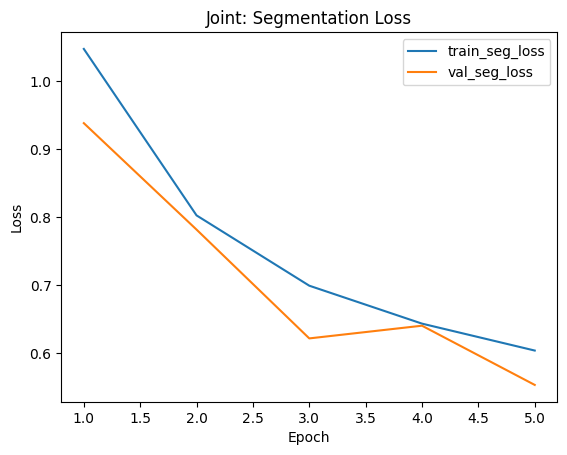

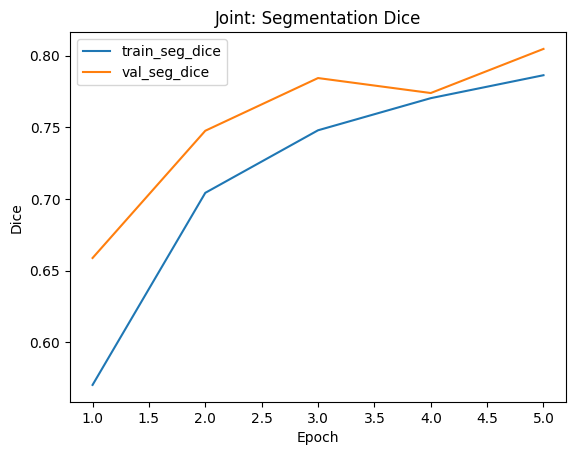

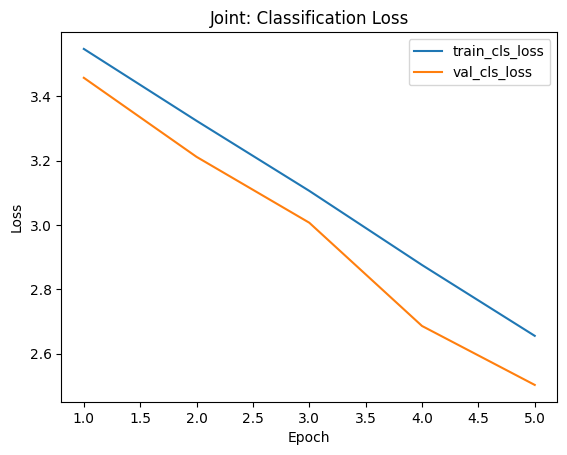

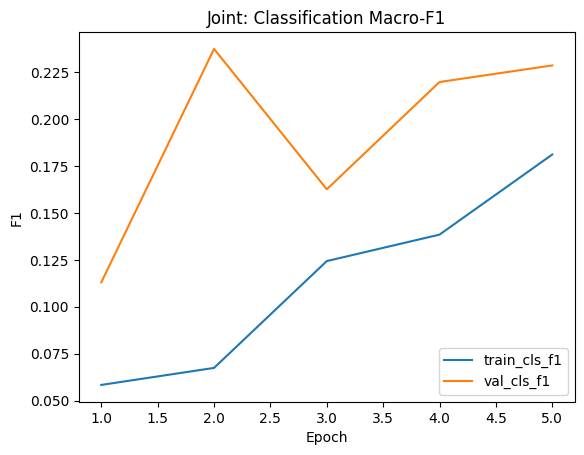

In [ ]:
#  Joint training curves (loss + key metrics)

import numpy as np
import matplotlib.pyplot as plt

ep = np.arange(1, len(hist["train_seg_loss"]) + 1)

plt.figure()
plt.plot(ep, hist["train_seg_loss"], label="train_seg_loss")
plt.plot(ep, hist["val_seg_loss"], label="val_seg_loss")
plt.title("Joint: Segmentation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

plt.figure()
plt.plot(ep, hist["train_seg_dice"], label="train_seg_dice")
plt.plot(ep, hist["val_seg_dice"], label="val_seg_dice")
plt.title("Joint: Segmentation Dice")
plt.xlabel("Epoch"); plt.ylabel("Dice"); plt.legend(); plt.show()

plt.figure()
plt.plot(ep, hist["train_cls_loss"], label="train_cls_loss")
plt.plot(ep, hist["val_cls_loss"], label="val_cls_loss")
plt.title("Joint: Classification Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

plt.figure()
plt.plot(ep, hist["train_cls_f1"], label="train_cls_f1")
plt.plot(ep, hist["val_cls_f1"], label="val_cls_f1")
plt.title("Joint: Classification Macro-F1")
plt.xlabel("Epoch"); plt.ylabel("F1"); plt.legend(); plt.show()


inferance

In [ ]:
CODE_TO_LABEL = {
    "ab": "Abyssinian", "be": "Bengal", "bi": "Birman", "bo": "Bombay",
    "br": "British_Shorthair", "eg": "Egyptian_Mau", "ma": "Maine_Coon", "pe": "Persian",
    "ra": "Ragdoll", "ru": "Russian_Blue", "si": "Siamese", "sp": "Sphynx",
    "ab2": "american_bulldog", "ap": "american_pit_bull_terrier", "ba": "basset_hound",
    "bea": "beagle", "bx": "boxer", "ch": "chihuahua", "ec": "english_cocker_spaniel",
    "es": "english_setter", "gs": "german_shorthaired", "gp": "great_pyrenees",
    "hav": "havanese", "jc": "japanese_chin", "ke": "keeshond", "le": "leonberger",
    "mp": "miniature_pinscher", "nf": "newfoundland", "pom": "pomeranian", "pug": "pug",
    "sb": "saint_bernard", "sam": "samoyed", "sc": "scottish_terrier",
    "sh": "shiba_inu", "st": "staffordshire_bull_terrier",
    "wt": "wheaten_terrier", "yo": "yorkshire_terrier"
}

def infer_true_label(image_path: str):

    parts = image_path.replace("\\", "/").split("/")
    if "classification_task" in parts:
        i = parts.index("classification_task")
        if i + 2 < len(parts):
            split = parts[i + 1]
            lab = parts[i + 2]
            if split in ("train", "test"):
                return lab


    fname = os.path.basename(image_path)
    toks = fname.split("_")
    if len(toks) >= 4:
        code = toks[3].lower()
        return CODE_TO_LABEL.get(code, None)

    return None

def find_gt_mask(image_path: str, data_root: str):
    base = os.path.splitext(os.path.basename(image_path))[0] + ".png"
    for c in [
        os.path.join(data_root, "segmentation_task/train/masks", base),
        os.path.join(data_root, "segmentation_task/test/masks", base),
    ]:
        if os.path.exists(c):
            return c
    return None

@torch.no_grad()
def demo_joint_project_inference(
    image_path: str,
    joint_model,
    label_map,
    img_size=(384, 384),
    thr=0.5,
    data_root=paths.data_root,
):
    joint_model.eval()
    device = next(joint_model.parameters()).device

    # ---- load + processed (resize) ----
    img_orig = Image.open(image_path).convert("L")
    img_proc = TF.resize(img_orig, img_size, interpolation=InterpolationMode.BILINEAR)
    x = TF.to_tensor(img_proc).unsqueeze(0).to(device)

    # ---- GT mask  ----
    mask_path = find_gt_mask(image_path, data_root)
    gt_mask = None
    if mask_path is not None:
        m = Image.open(mask_path).convert("L")
        m = TF.resize(m, img_size, interpolation=InterpolationMode.NEAREST)
        gt_mask = (np.array(m) > 0).astype(np.float32)

    # ---- joint predictions ----
    seg_logits = joint_model.forward_seg(x)
    seg_prob = torch.sigmoid(seg_logits)[0, 0].detach().cpu().numpy()
    pred_mask = (seg_prob > thr).astype(np.float32)

    cls_logits = joint_model.forward_cls(x)
    probs = torch.softmax(cls_logits, dim=1)[0].detach().cpu().numpy()
    pred_id = int(np.argmax(probs))
    pred_label = label_map.id_to_label[pred_id]
    pred_conf = float(probs[pred_id])


    iou = None
    if gt_mask is not None:
        tp = (pred_mask * gt_mask).sum()
        fp = (pred_mask * (1 - gt_mask)).sum()
        fn = ((1 - pred_mask) * gt_mask).sum()
        eps = 1e-7
        iou = float((tp + eps) / (tp + fp + fn + eps))

    # ---- given/predicted + single-image cls "accuracy"  ----
    given = infer_true_label(image_path)
    cls_acc = None
    if given is not None:
        cls_acc = 1.0 if pred_label == given else 0.0

    # ---- plot: exact 2×3 project layout ----
    img_np = np.array(img_proc)
    fig, ax = plt.subplots(2, 3, figsize=(14, 8))

    ax[0, 0].imshow(img_np, cmap="gray"); ax[0, 0].set_title("Original image"); ax[0, 0].axis("off")

    if gt_mask is None:
        ax[0, 1].imshow(np.zeros_like(img_np), cmap="gray")
    else:
        ax[0, 1].imshow(gt_mask, cmap="jet")
    ax[0, 1].set_title("Original mask"); ax[0, 1].axis("off")

    ax[0, 2].imshow(img_np, cmap="gray")
    if gt_mask is not None:
        ax[0, 2].imshow(gt_mask, cmap="jet", alpha=0.35)
    ax[0, 2].set_title("Original image with mask overlay"); ax[0, 2].axis("off")

    ax[1, 0].imshow(img_np, cmap="gray")
    ax[1, 0].set_title("Processed image ")
    ax[1, 0].axis("off")

    ax[1, 1].imshow(pred_mask, cmap="jet"); ax[1, 1].set_title("Predicted mask"); ax[1, 1].axis("off")

    ax[1, 2].imshow(img_np, cmap="gray")
    ax[1, 2].imshow(pred_mask, cmap="jet", alpha=0.35)
    ax[1, 2].set_title("Original image with predicted mask overlay"); ax[1, 2].axis("off")

    given_txt = "N/A" if given is None else given
    acc_txt   = "N/A" if cls_acc is None else f"{cls_acc:.2f}"
    iou_txt   = "N/A" if iou is None else f"{iou:.3f}"
    fig.suptitle(
        f"given: {given_txt}   predicted: {pred_label} ({pred_conf:.2f})   classification accuracy - {acc_txt}   IoU - {iou_txt}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


Analysis:

Compared to training the segmentation and classification heads separately, joint training with a shared encoder gave better overall performance and the loss curves support that trend. In the separate setup, Stage-1 segmentation loss decreased smoothly and stabilized (with val loss tracking train loss closely), and the final segmentation metrics were strong (test mIoU = 0.8411, Dice = 0.8165, pixel accuracy = 0.9924). However, the Stage-2 classifier (trained after freezing the encoder) showed a slower decrease and a clear gap between train and validation loss, ending with much lower classification performance (test accuracy = 0.7930, F1 = 0.7923).

In joint training, both the segmentation and classification losses generally decreased together and stayed low for most epochs (even though there were a few short validation spikes later in training), and the best checkpoint produced higher test performance on both tasks: segmentation improved slightly (test mIoU = 0.8510, Dice = 0.8297, pixel accuracy = 0.9931) while classification improved dramatically (test accuracy = 0.9740, F1 = 0.9740). Overall, based on both the loss-curve behavior and the final test metrics, the joint training approach was clearly better, especially for classification, while also providing a modest gain in segmentation quality.

joint training improve classification because:
 the encoder learns class-discriminative features directly from classification loss, instead of being frozen after segmentation-only training.

 segmentation also improve slightly because:

Multi-task learning acts like a regularizer: classification encourages encoder to learn robust global features that can also help segmentation generalization.

Bonus 2

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA_ROOT = oxford_pet_dataset_path
CLS_TRAIN_DIR = f"{DATA_ROOT}/classification_task/train"
CLS_TEST_DIR  = f"{DATA_ROOT}/classification_task/test"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 2
PATIENCE = 5
LR = 1e-3

LABELS = [
    "Abyssinian", "Bengal", "Birman", "Bombay", "British_Shorthair",
    "Egyptian_Mau", "Maine_Coon", "Persian", "Ragdoll", "Russian_Blue",
    "Siamese", "Sphynx", "american_bulldog", "american_pit_bull_terrier",
    "basset_hound", "beagle", "boxer", "chihuahua", "english_cocker_spaniel",
    "english_setter", "german_shorthaired", "great_pyrenees", "havanese",
    "japanese_chin", "keeshond", "leonberger", "miniature_pinscher",
    "newfoundland", "pomeranian", "pug", "saint_bernard", "samoyed",
    "scottish_terrier", "shiba_inu", "staffordshire_bull_terrier",
    "wheaten_terrier", "yorkshire_terrier"
]
LABEL_TO_ID = {l:i for i,l in enumerate(LABELS)}
ID_TO_LABEL = {i:l for l,i in LABEL_TO_ID.items()}

print("Device:", DEVICE)
print("Train dir:", CLS_TRAIN_DIR)
print("Test  dir:", CLS_TEST_DIR)

Device: cuda
Train dir: /kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/classification_task/train
Test  dir: /kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/classification_task/test


In [ ]:
import os
import re
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

def get_class_from_filename(fname):
    # Example: Abyssinian_100.jpg -> Abyssinian
    m = re.match(r"^(.+)_\d+\.(jpg|jpeg|png)$", fname, flags=re.IGNORECASE)
    return m.group(1) if m else None

def build_cls_df_from_images(images_dir):
    if not os.path.isdir(images_dir):
        raise FileNotFoundError(f"Images folder not found: {images_dir}")

    rows = []
    for fn in os.listdir(images_dir):
        if not fn.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        cls = get_class_from_filename(fn)
        if cls is None:
            continue
        rows.append({
            "path": os.path.join(images_dir, fn),
            "label": cls
        })

    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError(f"No valid images found in {images_dir}")

    labels_sorted = sorted(df["label"].unique())
    label_to_id = {lab: i for i, lab in enumerate(labels_sorted)}
    df["y"] = df["label"].map(label_to_id).astype(int)

    return df, label_to_id

# Use the real dataset structure
images_dir = os.path.join(DATA_ROOT, "images")
df_all, label_to_id = build_cls_df_from_images(images_dir)

# train / temp
df_train, df_temp = train_test_split(
    df_all,
    test_size=0.2,
    random_state=SEED,
    stratify=df_all["y"]
)

# val / test from temp (10% + 10% overall)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=df_temp["y"]
)

print("Train:", len(df_train), "Val:", len(df_val), "Test:", len(df_test))
print("Num classes:", len(label_to_id))
df_train.head()

Train: 5912 Val: 739 Test: 739
Num classes: 37


,path,label,y
553,/kaggle/input/datasets/julinmaloof/the-oxfordi...,Russian_Blue,9
5011,/kaggle/input/datasets/julinmaloof/the-oxfordi...,german_shorthaired,20
2135,/kaggle/input/datasets/julinmaloof/the-oxfordi...,scottish_terrier,32
5683,/kaggle/input/datasets/julinmaloof/the-oxfordi...,wheaten_terrier,35
3528,/kaggle/input/datasets/julinmaloof/the-oxfordi...,basset_hound,14


In [ ]:
# =========================================================
# convert to 3-channel
# =========================================================
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_tfms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class OxfordPetClsDatasetRGB(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        p = self.df.loc[idx, "path"]
        y = int(self.df.loc[idx, "y"])
        # convert to RGB (repeats grayscale into 3 channels)
        img = Image.open(p).convert("RGB")
        x = self.transform(img)
        return x, y

In [ ]:
# =========================================================
# DataLoaders
# =========================================================
train_loader = DataLoader(OxfordPetClsDatasetRGB(df_train, train_tfms), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(OxfordPetClsDatasetRGB(df_val,   eval_tfms),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(OxfordPetClsDatasetRGB(df_test,  eval_tfms),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


In [ ]:
# =========================================================
#  Metrics helpers (acc, precision_macro, recall_macro, f1_macro)
# =========================================================
def cls_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return float(acc), float(p), float(r), float(f1)


In [ ]:
# =========================================================
#  MobileNetV2, EfficientNet-B0, DenseNet121
# =========================================================
def _try_weights(getter):
    try:
        return getter.DEFAULT
    except Exception:
        return None

def get_model(model_name: str, num_classes: int):
    model_name = model_name.lower()

    if model_name == "mobilenetv2":
        weights = _try_weights(torchvision.models.MobileNet_V2_Weights)
        try:
            m = torchvision.models.mobilenet_v2(weights=weights)
        except Exception:
            m = torchvision.models.mobilenet_v2(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m

    if model_name == "efficientnetb0":
        weights = _try_weights(torchvision.models.EfficientNet_B0_Weights)
        try:
            m = torchvision.models.efficientnet_b0(weights=weights)
        except Exception:
            m = torchvision.models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m

    if model_name == "densenet121":
        weights = _try_weights(torchvision.models.DenseNet121_Weights)
        try:
            m = torchvision.models.densenet121(weights=weights)
        except Exception:
            m = torchvision.models.densenet121(weights=None)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
        return m

    raise ValueError("Unknown model_name. Use: mobilenetv2, efficientnetb0, densenet121")


In [ ]:
# =========================================================
# Train/Eval one epoch
# =========================================================
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    all_true, all_pred = [], []

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        all_true.extend(y.detach().cpu().numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc, p, r, f1 = cls_metrics(all_true, all_pred)
    return avg_loss, acc, p, r, f1

@torch.no_grad()
def eval_one_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_true, all_pred = [], []

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        all_true.extend(y.detach().cpu().numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc, p, r, f1 = cls_metrics(all_true, all_pred)
    return avg_loss, acc, p, r, f1


In [ ]:
# =========================================================
#  Full training runner for 1 architecture
# =========================================================
def train_model(model_name: str):
    model = get_model(model_name, num_classes=len(LABELS)).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    best_val_f1 = -1.0
    best_path = f"/kaggle/working/{model_name}_best.pth"
    no_improve = 0

    hist = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}

    for epoch in range(1, EPOCHS + 1):
        tr = train_one_epoch(model, train_loader, optimizer, criterion)
        va = eval_one_epoch(model, val_loader, criterion)

        tr_loss, tr_acc, _, _, tr_f1 = tr
        va_loss, va_acc, _, _, va_f1 = va

        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(va_loss)
        hist["train_f1"].append(tr_f1)
        hist["val_f1"].append(va_f1)

        print(f"[{model_name}] Epoch {epoch:02d}/{EPOCHS} | "
              f"loss {tr_loss:.4f}/{va_loss:.4f} | "
              f"acc {tr_acc:.4f}/{va_acc:.4f} | "
              f"F1 {tr_f1:.4f}/{va_f1:.4f}")

        if va_f1 > best_val_f1 + 1e-4:
            best_val_f1 = va_f1
            no_improve = 0
            torch.save(model.state_dict(), best_path)
            print(f"Saved best: {best_path} (val_F1={best_val_f1:.4f})")
        else:
            no_improve += 1

        if no_improve >= PATIENCE:
            print(f"  Early stopping (no improve for {PATIENCE} epochs).")
            break

    # Load best + final summaries
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))

    tr = eval_one_epoch(model, train_loader, criterion)
    va = eval_one_epoch(model, val_loader, criterion)
    te = eval_one_epoch(model, test_loader, criterion)

    summary = pd.DataFrame(
        [["train", *tr], ["val", *va], ["test", *te]],
        columns=["split", "loss", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
    )
    return model, best_path, hist, summary

In [ ]:
# =========================================================
#  3 architectures + show comparison table
# =========================================================
models_to_try = ["mobilenetv2", "efficientnetb0", "densenet121"]

all_summaries = []
all_histories = {}
best_paths = {}

for name in models_to_try:
    model, path, hist, summary = train_model(name)
    best_paths[name] = path
    all_histories[name] = hist

    # keep ONLY test row for the final comparison table
    test_row = summary[summary["split"] == "test"].copy()
    test_row.insert(0, "model", name)
    all_summaries.append(test_row)

comparison = pd.concat(all_summaries, ignore_index=True)
comparison


[mobilenetv2] Epoch 01/2 | loss 1.0678/0.7276 | acc 0.6828/0.7727 | F1 0.6842/0.7708
Saved best: /kaggle/working/mobilenetv2_best.pth (val_F1=0.7708)
[mobilenetv2] Epoch 02/2 | loss 0.5125/0.5415 | acc 0.8336/0.8227 | F1 0.8330/0.8222
Saved best: /kaggle/working/mobilenetv2_best.pth (val_F1=0.8222)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 125MB/s] 


[efficientnetb0] Epoch 01/2 | loss 1.0699/0.6521 | acc 0.6883/0.7997 | F1 0.6880/0.7957
Saved best: /kaggle/working/efficientnetb0_best.pth (val_F1=0.7957)
[efficientnetb0] Epoch 02/2 | loss 0.4908/0.5155 | acc 0.8439/0.8336 | F1 0.8434/0.8342
Saved best: /kaggle/working/efficientnetb0_best.pth (val_F1=0.8342)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 51.2MB/s]


[densenet121] Epoch 01/2 | loss 1.3026/1.1401 | acc 0.6187/0.6576 | F1 0.6166/0.6463
Saved best: /kaggle/working/densenet121_best.pth (val_F1=0.6463)
[densenet121] Epoch 02/2 | loss 0.7624/0.8566 | acc 0.7558/0.7267 | F1 0.7551/0.7193
Saved best: /kaggle/working/densenet121_best.pth (val_F1=0.7193)


,model,split,loss,accuracy,precision_macro,recall_macro,f1_macro
0,mobilenetv2,test,0.513744,0.838972,0.850551,0.838691,0.837574
1,efficientnetb0,test,0.498320,0.857916,0.880523,0.857895,0.856957
2,densenet121,test,0.820910,0.746955,0.771645,0.746799,0.743922


In [ ]:
# =========================================================
# clean comparison
# =========================================================
comparison_sorted = comparison.sort_values(by="f1_macro", ascending=False)

print(comparison_sorted.to_string(index=False))
print("\nBest checkpoints:", best_paths)


         model split     loss  accuracy  precision_macro  recall_macro  f1_macro
efficientnetb0  test 0.498320  0.857916         0.880523      0.857895  0.856957
   mobilenetv2  test 0.513744  0.838972         0.850551      0.838691  0.837574
   densenet121  test 0.820910  0.746955         0.771645      0.746799  0.743922

Best checkpoints: {'mobilenetv2': '/kaggle/working/mobilenetv2_best.pth', 'efficientnetb0': '/kaggle/working/efficientnetb0_best.pth', 'densenet121': '/kaggle/working/densenet121_best.pth'}


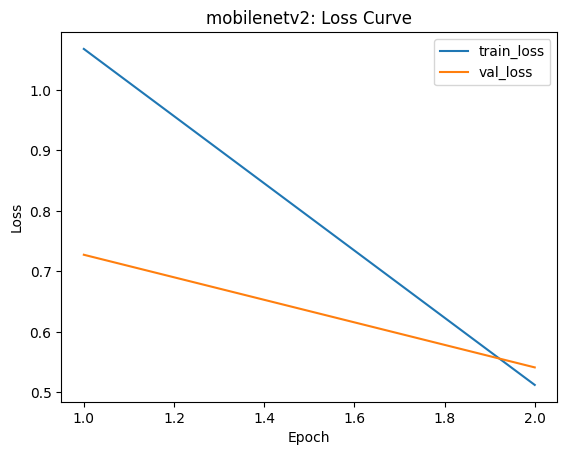

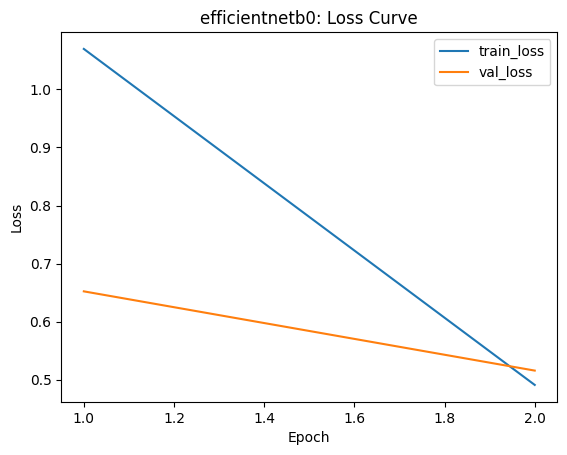

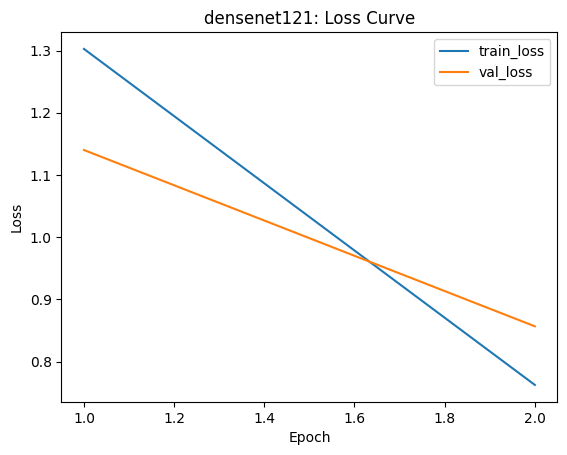

In [ ]:
# =========================================================
#  Loss curves (train vs val) for the 3 architectures

for name in models_to_try:
    hist = all_histories[name]
    ep = np.arange(1, len(hist["train_loss"]) + 1)

    plt.figure()
    plt.plot(ep, hist["train_loss"], label="train_loss")
    plt.plot(ep, hist["val_loss"], label="val_loss")
    plt.title(f"{name}: Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()
